# AV2 — Ciência de Dados (CESMAC) · Notebook único do grupo

**Dataset:** custos de seguro médico (`insurance.csv`) · **Alvo:** `charges`

| Parte | Responsável | Conteúdo |
|---|---|---|
| 1 | Pedro Victhor Monteiro | Importação, diagnóstico, limpeza e preparação |
| 2 | Eduardo Souza de Barros | EDA e insights |
| 3 | Eduardo Souza de Barros | Regressão e validação cruzada |
| 4 | Eduardo Souza de Barros | Ridge, avaliação final no teste, análise de erros e conclusão |

O notebook deve ser executado do início ao fim (**Reiniciar e executar tudo**), com `insurance.csv` na mesma pasta. Cada parte reutiliza as variáveis criadas pelas anteriores (`df_original`, `df_preparado`, `X_treino`, `X_teste`, `y_treino`, `y_teste`, `kf`, `registro_decisoes`).

# AV2 — Parte 1: Importação, Diagnóstico, Limpeza e Preparação

**Dataset:** `insurance.csv`  
**Variável alvo:** `charges`  

Ao terminar esta parte você deve ter:
- `df_original` com os dados brutos
- `df_preparado` limpo e pronto para as próximas partes
- um registro escrito de cada decisão que tomou e por quê

## 1. Ambiente

Importe as bibliotecas que vai precisar (pandas, numpy, matplotlib, seaborn).

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


## 2. Importação

Carregue o `insurance.csv` e salve em `df_original`.  
Mostre as dimensões e as primeiras linhas para confirmar que carregou certo.

In [2]:
df_original = pd.read_csv("insurance.csv")

print(df_original.shape)
df_original.head()


(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Diagnóstico

Antes de mexer em qualquer coisa, entenda o que você tem. Responda (com código + texto):

- Quais são as colunas e seus tipos?
- Há valores ausentes? Em quais colunas?
- Há linhas duplicadas?
- Como está distribuída a variável `charges`? (use `describe()` e um gráfico)

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
1
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


<Axes: xlabel='charges', ylabel='Count'>

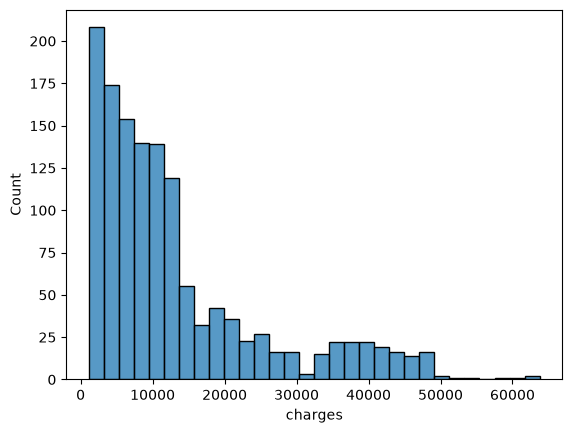

In [3]:
print(df_original.dtypes)
print(df_original.isna().sum())
print(df_original.duplicated().sum())
print(df_original.describe())

sns.histplot(data=df_original, x="charges")


**Suas observações:** 

tipos das colunas: numericas e categoricas
ausências: 0 ausências
duplicatas: 1
charges: min: ~1.121,87 | max: ~63.770,42 | média: ~13.270,42 | mediana: ~9.382,03 | desvio padrão: ~12.000,00

## 4. Limpeza

Com base no que encontrou no diagnóstico, tome as decisões necessárias.  
Para cada decisão, **escreva o motivo** na célula markdown abaixo do código.

In [4]:
df_preparado = df_original.drop_duplicates()

assert len(df_preparado) == 1337, "Ainda tem duplicata"

**Decisões tomadas:**
- Decisão 1: A duplicata encontrada foi removida, pois ela poderia distorcer análises futuras.
- Decisão 2: Não tem ausências, então não foi necessário tratar valores nulos.

## 5. Preparação

Crie as colunas derivadas que achar úteis para a EDA da Parte 2 (ex: faixas de valores, categorias clínicas).  
Lembre: **normalização e encoding categórico ficam nas Partes 3 e 4**, dentro dos Pipelines.  
Salve o resultado em `df_preparado`.

In [5]:
df_preparado["age_group"] = pd.cut(df_preparado["age"], bins=[17, 30, 45, 64], labels=["jovem", "adulto", "senior"])
df_preparado["faixa_charges"] = pd.cut(df_preparado["charges"], bins=[0, 10000, 30000, 65000], labels=["baixo", "médio", "alto"])
df_preparado["bmi_categoria"] = pd.cut(df_preparado["bmi"], bins=[0, 18.5, 25, 30, float("inf")], labels=["abaixo_peso", "normal", "sobrepeso", "obesidade"])


**Por que criou essas colunas?**
Para uma analise mais detalhada dos dados, foi criado três novas colunas:
- `bmi_categoria`: para categorizar os valores de IMC (BMI) em categorias.
- `age_group`: para categorizar os valores de idade em faixas etárias.
- `faixa_charges`: para categorizar os valores de charges em faixas de valores.


## 6. Verificação final

Confirme que `df_preparado` está correto antes de exportar:
- dimensões fazem sentido?
- sem ausências?
- sem duplicatas?

In [6]:
print(df_preparado.shape)
print(df_preparado.isna().sum())
print(df_preparado.duplicated().sum())

(1337, 10)
age              0
sex              0
bmi              0
children         0
smoker           0
region           0
charges          0
age_group        0
faixa_charges    0
bmi_categoria    0
dtype: int64
0


## 7. Exportação

Salve `df_preparado` como `insurance_preparado.csv` — as Partes 2, 3 e 4 vão carregar esse arquivo.

In [7]:
df_preparado.to_csv("insurance_preparado.csv", index=False)


# AV2 — Parte 2: Análise Exploratória de Dados (EDA) e insights

**Ciência de Dados — CESMAC | Dataset: custos de seguro médico (`insurance.csv`)**

> **Ideia central:** EDA é uma investigação orientada por perguntas. Cada resultado vira uma afirmação sustentada por evidência e acompanhada por uma limitação.

| Parte | Responsável | Conteúdo |
|---|---|---|
| 1 | Pedro Victhor Monteiro | Importação, diagnóstico, limpeza e preparação (`df_original` → `df_preparado`) |
| **2** | **Eduardo Souza de Barros** | **EDA e insights (este notebook)** |
| 3 | Eduardo Souza de Barros | Regressão e validação cruzada |
| 4 | Eduardo Souza de Barros | Ridge, avaliação final no teste, análise de erros e conclusão |

## A. Objetivo e integração

**Objetivo.** Investigar como as despesas médicas (`charges`) se distribuem e como variam com as demais variáveis, antes da modelagem. `charges` é a **variável-alvo** da regressão que será construída nas Partes 3 e 4.

A EDA procura:

1. **padrões** na distribuição de `charges` (centro, dispersão, forma, valores extremos);
2. **diferenças entre grupos** (`smoker`, `region`, `sex`);
3. **relações** entre `charges` e as variáveis numéricas (`age`, `bmi`, `children`), inclusive se essas relações mudam entre fumantes e não fumantes;
4. **limitações** que as próximas partes devem considerar.

> **Associação não demonstra causalidade.** Os dados são observacionais: mostram que grupos diferem, não *por que* diferem.

**Unidade monetária.** O repositório não traz dicionário de dados. O conjunto é conhecido publicamente como *Medical Cost Personal Datasets*; adotamos a **suposição explícita** de que `charges` está em **dólares americanos (US$)**. Essa unidade não foi confirmada formalmente.

**Integração com as demais partes.**

- Este notebook recebe `df_preparado` da Parte 1. Quando o notebook único for montado, a célula **"Integração"** abaixo detecta que `df_original` e `df_preparado` já existem e **não recarrega nada**.
- Executado sozinho, ele carrega o CSV e reproduz *apenas* a decisão da Parte 1 sobre a duplicata, para poder rodar do início ao fim. Essa reprodução não substitui a Parte 1.
- A EDA **não** faz `train_test_split`, **não** acessa o conjunto de teste e **não** cria modelos.
- A EDA **não altera** `df_original` nem `df_preparado`: análises auxiliares usam a cópia `df_eda`. A Parte 2 não cria nenhuma coluna em `df_preparado`.

> **Observação metodológica:** a EDA foi feita sobre a base preparada completa, antes da divisão treino/teste da Parte 3. Por isso, os achados aqui servem para **orientar** hipóteses, não para escolher variáveis "olhando" o desempenho no teste. O desempenho real dos modelos será medido pelas Partes 3 e 4.

## 1. Ambiente

In [8]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

AZUL = "#3D8DFF"
LARANJA = "#C2611F"
CINZA = "#5F6B7A"
CORES_FUMANTE = {"no": AZUL, "yes": LARANJA}
ROTULOS_FUMANTE = {"no": "Não fumante", "yes": "Fumante"}
RANDOM_STATE = 42  # convenção do grupo (esta parte não usa aleatoriedade)

## 2. Integração com a Parte 1

Esta célula é o **ponto de encaixe** no notebook único do grupo.

- Se `df_preparado` já existir (vindo da Parte 1), ela é usada como está.
- Caso contrário (execução isolada), o CSV é carregado em `df_original` e a única decisão conhecida da Parte 1 é reproduzida: **remoção da linha duplicada integral**.

O SHA-256 do arquivo é conferido com o valor esperado. Se divergir, o notebook **avisa** em vez de falhar, porque o arquivo oficial do professor ainda pode chegar diferente; nesse caso a diferença precisa ser investigada antes da entrega.

In [9]:
SHA256_ESPERADO = "505c1cbc2e63d0363bac59501563df2530aadf4cdb9cfee226f4ef32f5468281"
CANDIDATOS = [
    Path("insurance.csv"),
    Path("dados/insurance.csv"),
    Path("../AV2/insurance.csv"),
    Path("AV2/insurance.csv"),
]

def sha256_arquivo(caminho):
    return hashlib.sha256(Path(caminho).read_bytes()).hexdigest()

if "df_preparado" in globals():
    origem = "Parte 1 (df_preparado já existente no notebook)"
    print("Integração: usando df_original e df_preparado criados pela Parte 1.")
else:
    caminho = next((p for p in CANDIDATOS if p.exists()), None)
    assert caminho is not None, f"insurance.csv não encontrado. Procurado em: {[str(p) for p in CANDIDATOS]}"
    origem = str(caminho)

    hash_obtido = sha256_arquivo(caminho)
    if hash_obtido == SHA256_ESPERADO:
        print(f"SHA-256 confere com o esperado: {hash_obtido}")
    else:
        print("ATENÇÃO: SHA-256 DIFERENTE do esperado. Investigue antes de entregar.")
        print(f"  esperado: {SHA256_ESPERADO}\n  obtido:   {hash_obtido}")

    df_original = pd.read_csv(caminho)
    # Reprodução da decisão da Parte 1 (apenas para execução isolada):
    df_preparado = df_original.drop_duplicates().reset_index(drop=True)
    print("Execução isolada: duplicata integral removida em uma cópia (decisão da Parte 1).")

print("Origem dos dados:", origem)

# Colunas recebidas da Parte 1 (usadas na verificação final desta parte)
COLUNAS_ORIGINAIS = ["age", "sex", "bmi", "children", "smoker", "region", "charges"]
colunas_recebidas = list(df_preparado.columns)
colunas_auxiliares_parte1 = [c for c in colunas_recebidas if c not in COLUNAS_ORIGINAIS]

# Colunas calculadas a partir do alvo: NÃO podem ser preditoras nas Partes 3 e 4 (vazamento)
COLUNAS_DERIVADAS_DO_ALVO = [c for c in ["faixa_charges"] if c in colunas_recebidas]

print("Colunas auxiliares criadas na Parte 1:", colunas_auxiliares_parte1 or "nenhuma")
print("Derivadas de charges (excluir dos preditores):", COLUNAS_DERIVADAS_DO_ALVO or "nenhuma")

Integração: usando df_original e df_preparado criados pela Parte 1.
Origem dos dados: Parte 1 (df_preparado já existente no notebook)
Colunas auxiliares criadas na Parte 1: ['age_group', 'faixa_charges', 'bmi_categoria']
Derivadas de charges (excluir dos preditores): ['faixa_charges']


## B. Conferência da base

**Objetivo:** confirmar que a base recebida da Parte 1 está consistente (dimensões, tipos, ausências, duplicatas e categorias).

Não refazemos a limpeza da Parte 1; apenas confirmamos que o ponto de partida é consistente.

In [10]:
print("df_original :", df_original.shape)
print("df_preparado:", df_preparado.shape)
print("Linhas removidas na preparação:", len(df_original) - len(df_preparado))
print()
df_preparado.dtypes.to_frame("tipo")

df_original : (1338, 7)
df_preparado: (1337, 10)
Linhas removidas na preparação: 1



,tipo
age,int64
sex,str
bmi,float64
children,int64
smoker,str
region,str
charges,float64
age_group,category
faixa_charges,category
bmi_categoria,category


In [11]:
conferencia = pd.DataFrame({
    "valores_ausentes": df_preparado.isna().sum(),
    "valores_distintos": df_preparado.nunique(),
})
print("Duplicatas integrais em df_original :", df_original.duplicated().sum())
print("Duplicatas integrais em df_preparado:", df_preparado.duplicated().sum())
display(df_original[df_original.duplicated(keep=False)])
conferencia

Duplicatas integrais em df_original : 1
Duplicatas integrais em df_preparado: 0


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,"1,639.56"
581,19,male,30.59,0,no,northwest,"1,639.56"


,valores_ausentes,valores_distintos
age,0,47
sex,0,2
bmi,0,548
children,0,6
smoker,0,2
region,0,4
charges,0,1337
age_group,0,3
faixa_charges,0,3
bmi_categoria,0,4


In [12]:
for coluna in ["sex", "smoker", "region"]:
    espacos = (df_preparado[coluna] != df_preparado[coluna].str.strip()).sum()
    print(f"{coluna:7s} -> {sorted(df_preparado[coluna].unique())} | com espaços sobrando: {espacos}")

print()
print("Domínio age     :", df_preparado["age"].min(), "a", df_preparado["age"].max())
print("Domínio children:", df_preparado["children"].min(), "a", df_preparado["children"].max())
print("Valores <= 0 em bmi ou charges:", ((df_preparado["bmi"] <= 0) | (df_preparado["charges"] <= 0)).sum())

sex     -> ['female', 'male'] | com espaços sobrando: 0
smoker  -> ['no', 'yes'] | com espaços sobrando: 0
region  -> ['northeast', 'northwest', 'southeast', 'southwest'] | com espaços sobrando: 0

Domínio age     : 18 a 64
Domínio children: 0 a 5
Valores <= 0 em bmi ou charges: 0


In [13]:
df_preparado.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"1,337.00",39.22,14.04,18.00,27.00,39.00,51.00,64.00
bmi,"1,337.00",30.66,6.10,15.96,26.29,30.40,34.70,53.13
children,"1,337.00",1.10,1.21,0.00,0.00,1.00,2.00,5.00
charges,"1,337.00","13,279.12","12,110.36","1,121.87","4,746.34","9,386.16","16,657.72","63,770.43"


**Interpretação B.** A base preparada tem **1.337 linhas** e as 7 colunas originais (no notebook único, também as colunas auxiliares da Parte 1): o arquivo original tinha 1.338 linhas e uma duplicata integral (índices originais 195 e 581: `19, male, 30.59, 0, no, northwest, 1639.5631`), removida na preparação. Não há valores ausentes, não há espaços sobrando nas categorias e os domínios são plausíveis: `age` de 18 a 64, `children` de 0 a 5, nenhum `bmi` ou `charges` não positivo. As categorias são exatamente as esperadas (`female/male`, `no/yes` e quatro regiões). A EDA pode seguir sem novos tratamentos.

**Colunas auxiliares da Parte 1.** No notebook único, `df_preparado` chega com `age_group`, `bmi_categoria` e `faixa_charges`, criadas pela Parte 1 para apoiar a EDA. A EDA não as altera. **Atenção:** `faixa_charges` é calculada a partir de `charges` (o alvo). Ela pode ser usada para descrever os dados, mas **não pode entrar como variável preditora** nas Partes 3 e 4: o modelo estaria recebendo a resposta disfarçada (vazamento de informação do alvo). A lista `COLUNAS_DERIVADAS_DO_ALVO` existe para que as próximas partes a excluam explicitamente.

Como a base não tem coluna identificadora, não é possível garantir que as duas linhas duplicadas eram a mesma pessoa e não duas pessoas idênticas nas sete variáveis; a decisão de removê-la é da Parte 1 e impacta só 1 de 1.338 linhas.

In [14]:
# Cópia de trabalho da EDA: df_original e df_preparado não são alterados.
df_eda = df_preparado.copy()

## C. Análise univariada — distribuição de `charges`

**Objetivo:** descrever a distribuição das despesas médicas e comparar média e mediana.

In [15]:
resumo_charges = df_eda["charges"].describe().rename("charges (US$)")
media = df_eda["charges"].mean()
mediana = df_eda["charges"].median()
assimetria = df_eda["charges"].skew()

print(f"Média:      US$ {media:,.2f}")
print(f"Mediana:    US$ {mediana:,.2f}")
print(f"Média - mediana: US$ {media - mediana:,.2f} ({(media / mediana - 1) * 100:.1f}% acima da mediana)")
print(f"Assimetria: {assimetria:.2f}")
resumo_charges

Média:      US$ 13,279.12
Mediana:    US$ 9,386.16
Média - mediana: US$ 3,892.96 (41.5% acima da mediana)
Assimetria: 1.52


count    1,337.00
mean    13,279.12
std     12,110.36
min      1,121.87
25%      4,746.34
50%      9,386.16
75%     16,657.72
max     63,770.43
Name: charges (US$), dtype: float64

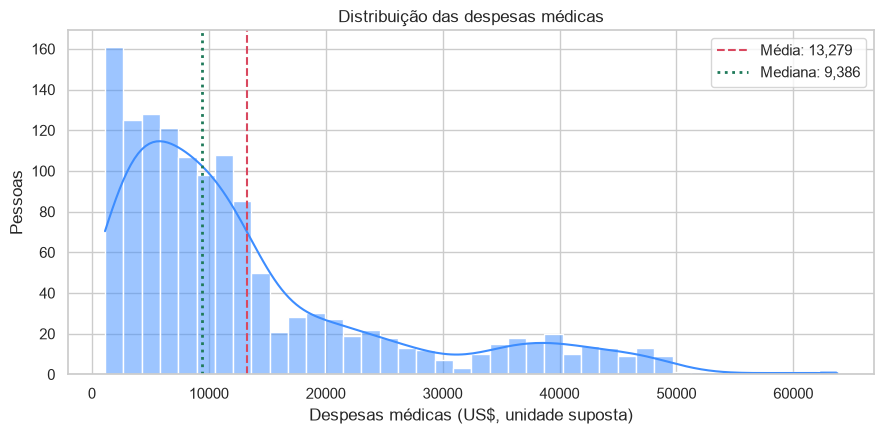

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df_eda, x="charges", bins=40, kde=True, color=AZUL, ax=ax)
ax.axvline(media, color="#D9485F", linestyle="--", label=f"Média: {media:,.0f}")
ax.axvline(mediana, color="#1F7A5A", linestyle=":", linewidth=2, label=f"Mediana: {mediana:,.0f}")
ax.set(title="Distribuição das despesas médicas", xlabel="Despesas médicas (US$, unidade suposta)", ylabel="Pessoas")
ax.legend()
plt.tight_layout()
plt.show()

### C.1 Boxplot e possíveis outliers (critério 1,5 × IQR)

In [17]:
q1, q3 = df_eda["charges"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
possiveis_outliers = df_eda.loc[~df_eda["charges"].between(limite_inferior, limite_superior)]

print(f"Q1: {q1:,.2f} | Q3: {q3:,.2f} | IQR: {iqr:,.2f}")
print(f"Limite inferior: {limite_inferior:,.2f} (negativo: nenhuma despesa pode ficar abaixo dele)")
print(f"Limite superior: {limite_superior:,.2f}")
print(f"Pontos acima do limite superior: {len(possiveis_outliers)} "
      f"({len(possiveis_outliers) / len(df_eda) * 100:.1f}% da base)")

Q1: 4,746.34 | Q3: 16,657.72 | IQR: 11,911.37
Limite inferior: -13,120.72 (negativo: nenhuma despesa pode ficar abaixo dele)
Limite superior: 34,524.78
Pontos acima do limite superior: 139 (10.4% da base)


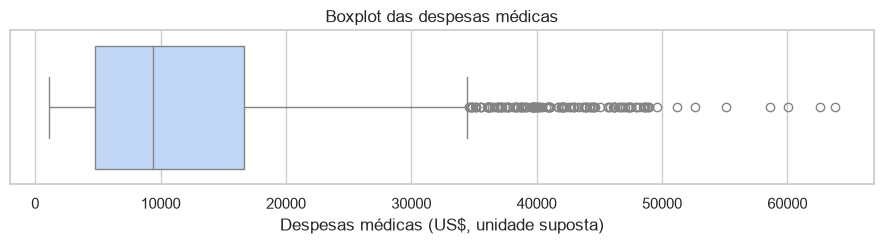

In [18]:
fig, ax = plt.subplots(figsize=(9, 2.6))
sns.boxplot(data=df_eda, x="charges", color="#B9D4FF", ax=ax)
ax.set(title="Boxplot das despesas médicas", xlabel="Despesas médicas (US$, unidade suposta)")
plt.tight_layout()
plt.show()

**Perfil dos pontos sinalizados.** Antes de tratar um ponto como "anormal", verificamos quem são essas pessoas.

In [19]:
perfil_outliers = pd.DataFrame({
    "n_sinalizados": possiveis_outliers["smoker"].value_counts(),
    "n_na_base": df_eda["smoker"].value_counts(),
})
perfil_outliers["%_dos_sinalizados"] = perfil_outliers["n_sinalizados"] / perfil_outliers["n_sinalizados"].sum() * 100
perfil_outliers["%_na_base"] = perfil_outliers["n_na_base"] / perfil_outliers["n_na_base"].sum() * 100
q1_fumantes = df_eda.loc[df_eda["smoker"] == "yes", "charges"].quantile(0.25)
pct_nao_fumantes_abaixo = (df_eda.loc[df_eda["smoker"] == "no", "charges"] < q1_fumantes).mean() * 100
print(f"Q1 dos fumantes: US$ {q1_fumantes:,.2f} | não fumantes abaixo desse valor: {pct_nao_fumantes_abaixo:.1f}%")
perfil_outliers.rename(index=ROTULOS_FUMANTE)

Q1 dos fumantes: US$ 20,826.24 | não fumantes abaixo desse valor: 94.9%


,n_sinalizados,n_na_base,%_dos_sinalizados,%_na_base
smoker,,,,
Não fumante,3,1063,2.16,79.51
Fumante,136,274,97.84,20.49


> **Outlier é um sinal para investigar, não uma ordem para excluir.** Um ponto distante pode ser erro, caso raro legítimo ou justamente a observação mais informativa. O critério do boxplot descreve distância; não conhece o contexto.

**Interpretação C.**

- **Afirmação:** `charges` é fortemente assimétrica à direita.
- **Evidência:** média de US$ 13.279,12 contra mediana de US$ 9.386,16 (a média fica cerca de US$ 3.893, ou 41,5%, acima da mediana); assimetria de **1,52**; desvio-padrão de US$ 12.110,36, quase do tamanho da média; valores entre US$ 1.121,87 e US$ 63.770,43. Três quartos das pessoas têm despesas até US$ 16.657,72 (Q3), e o histograma mostra uma cauda longa à direita.
- **Interpretação:** a média é "puxada" por uma minoria de custos altos; para descrever a pessoa típica, a mediana é mais representativa. Pelo critério 1,5 × IQR (limite superior de US$ 34.524,78), **139 registros (10,4%)** são sinalizados. Desses, **136 são fumantes** (97,8% dos sinalizados), embora fumantes sejam apenas 20,5% da base. Ou seja, os "outliers" não parecem erros isolados: formam um grupo coerente, ligado ao tabagismo, investigado na Seção D.
- **Limitação:** o critério 1,5 × IQR assume uma referência única para toda a base; em uma distribuição assimétrica e com subgrupos, ele sinaliza muitos casos legítimos. **Nenhum registro foi excluído.** A assimetria é uma informação para as Partes 3 e 4 (por exemplo, erros grandes tendem a se concentrar nos custos altos), não um motivo de remoção.

### C.2 Outras variáveis numéricas (visão rápida)

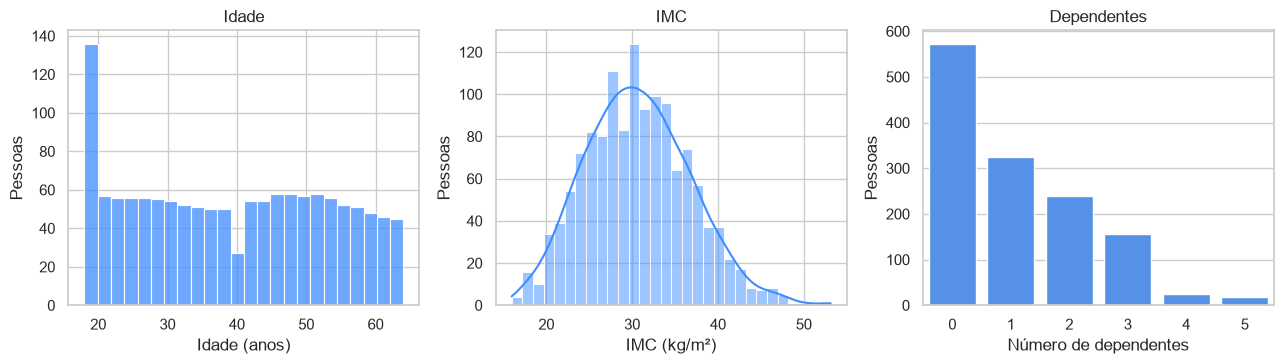

,mean,median,skew
age,39.22,39.00,0.05
bmi,30.66,30.40,0.28
children,1.10,1.00,0.94


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sns.histplot(data=df_eda, x="age", bins=24, color=AZUL, ax=axes[0])
axes[0].set(title="Idade", xlabel="Idade (anos)", ylabel="Pessoas")
sns.histplot(data=df_eda, x="bmi", bins=30, kde=True, color=AZUL, ax=axes[1])
axes[1].set(title="IMC", xlabel="IMC (kg/m²)", ylabel="Pessoas")
sns.countplot(data=df_eda, x="children", color=AZUL, ax=axes[2])
axes[2].set(title="Dependentes", xlabel="Número de dependentes", ylabel="Pessoas")
plt.tight_layout()
plt.show()

df_eda[["age", "bmi", "children"]].agg(["mean", "median", "skew"]).T

**Interpretação C.2.** `age` é aproximadamente uniforme entre 20 e 64 anos, com um acúmulo nas idades de 18–19 anos. `bmi` é aproximadamente simétrico (média 30,66 e mediana 30,40), centrado perto do limiar de obesidade da OMS (IMC 30). `children` é concentrada em 0–3: os grupos com 4 e 5 dependentes são muito pequenos (25 e 18 pessoas), o que torna qualquer comparação de custo nesses grupos instável.

## D. Comparação por grupos

**Objetivo:** comparar as despesas entre fumantes e não fumantes, entre regiões e entre sexos, considerando a dispersão e o tamanho de cada grupo.

Para cada variável: tabela com `n`, média, mediana e desvio-padrão (`groupby().agg()`) e boxplot.

In [21]:
def resumo_por_grupo(coluna):
    return (
        df_eda.groupby(coluna, observed=True)["charges"]
              .agg(n="count", media="mean", mediana="median", desvio_padrao="std")
              .sort_values("media", ascending=False)
    )

### D.1 `smoker`

In [22]:
charges_por_fumante = resumo_por_grupo("smoker")
razao_media = charges_por_fumante.loc["yes", "media"] / charges_por_fumante.loc["no", "media"]
razao_mediana = charges_por_fumante.loc["yes", "mediana"] / charges_por_fumante.loc["no", "mediana"]
print(f"Diferença de médias: US$ {charges_por_fumante.loc['yes', 'media'] - charges_por_fumante.loc['no', 'media']:,.2f}")
print(f"Razão das médias (fumante / não fumante):   {razao_media:.2f}")
print(f"Razão das medianas (fumante / não fumante): {razao_mediana:.2f}")
charges_por_fumante.rename(index=ROTULOS_FUMANTE)

Diferença de médias: US$ 23,609.57
Razão das médias (fumante / não fumante):   3.80
Razão das medianas (fumante / não fumante): 4.69


,n,media,mediana,desvio_padrao
smoker,,,,
Fumante,274,"32,050.23","34,456.35","11,541.55"
Não fumante,1063,"8,440.66","7,345.73","5,992.97"


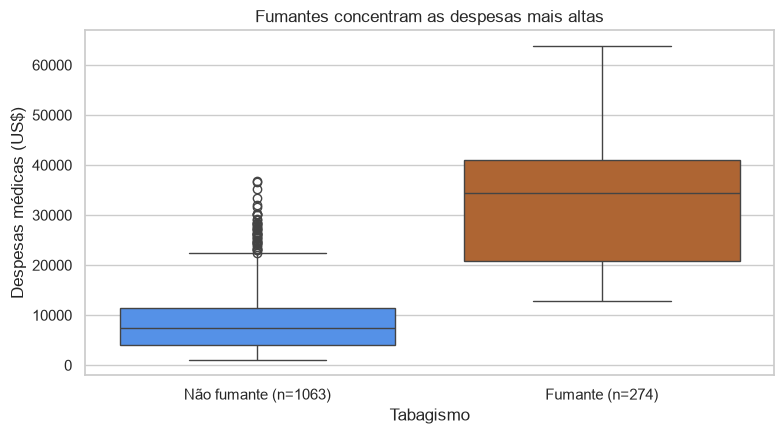

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_eda, x="smoker", y="charges", order=["no", "yes"],
            hue="smoker", palette=CORES_FUMANTE, legend=False, ax=ax)
ax.set_xticks([0, 1], [f"Não fumante (n={charges_por_fumante.loc['no', 'n']})",
                       f"Fumante (n={charges_por_fumante.loc['yes', 'n']})"])
ax.set(title="Fumantes concentram as despesas mais altas",
       xlabel="Tabagismo", ylabel="Despesas médicas (US$)")
plt.tight_layout()
plt.show()

**Interpretação D.1.** A diferença é grande e visível sem nenhum teste: a **mediana dos fumantes (US$ 34.456,35) é 4,69 vezes a dos não fumantes (US$ 7.345,73)**; nas médias, a razão é 3,80 (US$ 32.050,23 contra US$ 8.440,66). As caixas não se sobrepõem: o 1º quartil dos fumantes (US$ 20.826,24) está acima de 94,9% dos valores dos não fumantes, cujo 3º quartil é US$ 11.363,02. Os grupos são desiguais (274 fumantes contra 1.063 não fumantes), mas 274 é um grupo grande o suficiente para que a diferença não seja produto de poucos casos. O desvio-padrão dos fumantes (US$ 11.541,55) é quase o dobro do dos não fumantes, sugerindo que **dentro** dos fumantes há heterogeneidade (investigada na Seção E). É uma **associação** observada; não temos como isolar o efeito do fumo de outros fatores não medidos.

### D.2 `region`

In [24]:
charges_por_regiao = resumo_por_grupo("region")
charges_por_regiao

,n,media,mediana,desvio_padrao
region,,,,
southeast,364,"14,735.41","9,294.13","13,971.10"
northeast,324,"13,406.38","10,057.65","11,255.80"
northwest,324,"12,450.84","8,976.98","11,073.13"
southwest,325,"12,346.94","8,798.59","11,557.18"


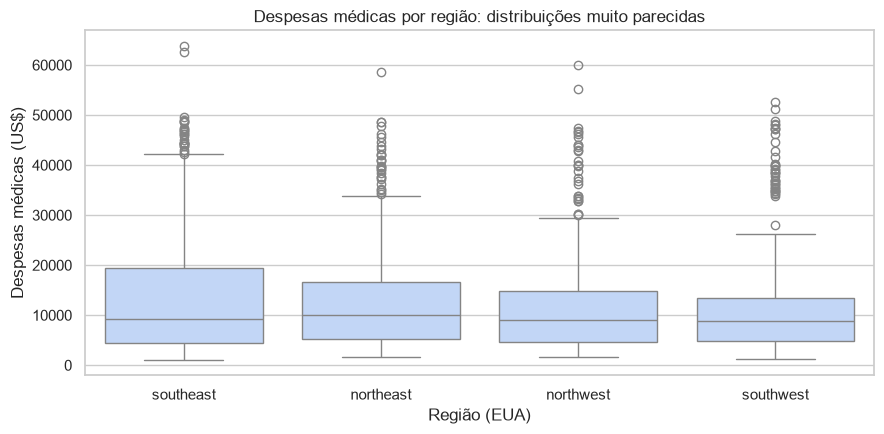

In [25]:
ordem = charges_por_regiao.index
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df_eda, x="region", y="charges", order=ordem, color="#B9D4FF", ax=ax)
ax.set(title="Despesas médicas por região: distribuições muito parecidas",
       xlabel="Região (EUA)", ylabel="Despesas médicas (US$)")
plt.tight_layout()
plt.show()

**Interpretação D.2.** `southeast` tem a maior média (US$ 14.735,41; n=364), cerca de US$ 2.400 acima de `southwest` (US$ 12.346,94). Mas essa diferença é pequena diante dos desvios-padrão (US$ 11 mil a 14 mil em todas as regiões), e **a ordem não se mantém pela mediana**: a maior mediana é a de `northeast` (US$ 10.057,65), enquanto a de `southeast` é US$ 9.294,13. A média maior de `southeast` vem da cauda de custos altos, não do custo típico. Os grupos são equilibrados (324 a 364 pessoas). Conclusão provisória: região mostra pouca diferença no custo típico; a Seção F verifica se a proporção de fumantes muda entre regiões, o que poderia explicar parte da cauda.

### D.3 `sex`

In [26]:
charges_por_sexo = resumo_por_grupo("sex")
charges_por_sexo

,n,media,mediana,desvio_padrao
sex,,,,
male,675,"13,975.00","9,377.90","12,971.96"
female,662,"12,569.58","9,412.96","11,128.70"


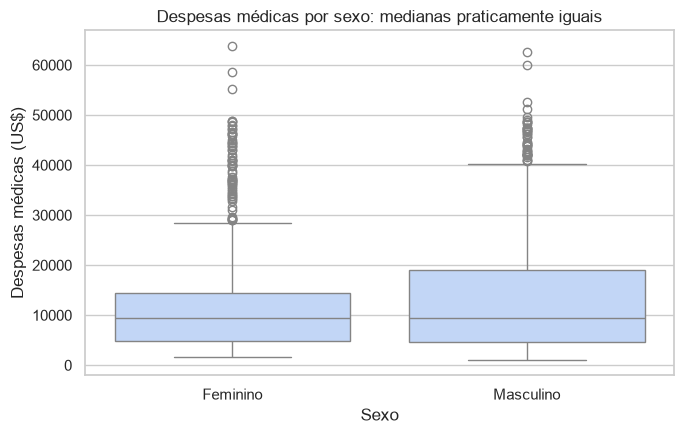

In [27]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df_eda, x="sex", y="charges", order=["female", "male"], color="#B9D4FF", ax=ax)
ax.set_xticks([0, 1], ["Feminino", "Masculino"])
ax.set(title="Despesas médicas por sexo: medianas praticamente iguais",
       xlabel="Sexo", ylabel="Despesas médicas (US$)")
plt.tight_layout()
plt.show()

**Sexo dentro de cada grupo de tabagismo.** Para verificar se a diferença por sexo reflete, em parte, a proporção de fumantes, comparamos os sexos **dentro** de cada grupo.

In [28]:
charges_sexo_fumante = (
    df_eda.groupby(["smoker", "sex"], observed=True)["charges"]
          .agg(n="count", media="mean", mediana="median", desvio_padrao="std")
)
charges_sexo_fumante

n     media   mediana  desvio_padrao
smoker sex                                           
no     female  547  8,762.30  7,639.42       6,060.78
       male    516  8,099.70  6,986.10       5,907.00
yes    female  115 30,679.00 28,950.47      11,907.54
       male    159 33,042.01 36,085.22      11,202.67

**Interpretação D.3.** Na base toda, homens têm média maior (US$ 13.975,00 contra US$ 12.569,58; diferença de ~US$ 1.405), mas as **medianas são praticamente iguais** (US$ 9.377,90 e US$ 9.412,96 — a feminina até um pouco maior). A diferença nas médias vem da cauda superior, não do custo típico.

Quando separamos por tabagismo, o padrão não se mantém de forma uniforme: **entre não fumantes, mulheres têm média maior** (US$ 8.762,30 contra US$ 8.099,70) e **entre fumantes, homens têm média maior** (US$ 33.042,01 contra US$ 30.679,00). Como há proporcionalmente mais fumantes entre os homens (verificado na Seção F), parte da diferença geral por sexo pode refletir a **composição** dos grupos, e não o sexo em si. Isso mostra por que comparar uma média isolada pode enganar.

### D.4 `children` (número de dependentes)

In [29]:
charges_por_dependentes = (
    df_eda.groupby("children", observed=True)["charges"]
          .agg(n="count", media="mean", mediana="median", desvio_padrao="std")
)
charges_por_dependentes

,n,media,mediana,desvio_padrao
children,,,,
0,573,"12,384.70","9,863.47","12,025.42"
1,324,"12,731.17","8,483.87","11,823.63"
2,240,"15,073.56","9,264.98","12,891.37"
3,157,"15,355.32","10,600.55","12,330.87"
4,25,"13,850.66","11,033.66","9,139.22"
5,18,"8,786.04","8,589.57","3,808.44"


**Interpretação D.4.** Não há tendência clara: a média sobe de 0 a 3 dependentes (US$ 12.384,70 → US$ 15.355,32) e cai com 5 (US$ 8.786,04), mas os grupos com 4 e 5 dependentes têm apenas **25 e 18 pessoas**, pequenos demais para conclusões firmes. As medianas oscilam entre US$ 8,5 mil e US$ 11 mil sem padrão monotônico. Tratamos `children` como associação fraca e incerta (confirmado na Seção E).

## E. Correlações

**Objetivo:** medir a direção e a intensidade da associação linear entre `charges` e `age`, `bmi` e `children`, e verificar se ela muda entre fumantes e não fumantes.

Pearson (`r`) mede **direção e força de uma relação linear**, de −1 a +1. O valor-p testa se `r` é diferente de zero. Um `r` próximo de zero **não** elimina relações curvas ou relações que só aparecem dentro de subgrupos.

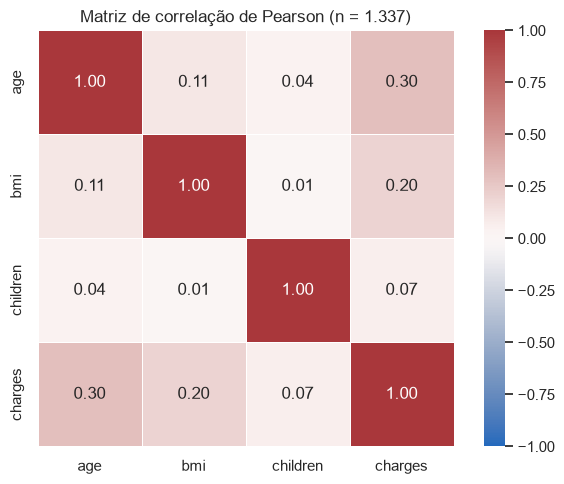

In [30]:
variaveis_numericas = ["age", "bmi", "children", "charges"]
corr = df_eda[variaveis_numericas].corr(method="pearson")

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Matriz de correlação de Pearson (n = 1.337)")
plt.tight_layout()
plt.show()

In [32]:
linhas = []
for variavel in ["age", "bmi", "children"]:
    resultado = stats.pearsonr(df_eda[variavel], df_eda["charges"])
    linhas.append({"variavel": variavel, "grupo": "todos", "n": len(df_eda),
                   "r": resultado.statistic, "valor_p": resultado.pvalue})
    for grupo, dados in df_eda.groupby("smoker", observed=True):
        resultado = stats.pearsonr(dados[variavel], dados["charges"])
        linhas.append({"variavel": variavel, "grupo": ROTULOS_FUMANTE[grupo], "n": len(dados),
                       "r": resultado.statistic, "valor_p": resultado.pvalue})

pearson_charges = pd.DataFrame(linhas)
pearson_charges.style.format({"r": "{:.3f}", "valor_p": "{:.2e}"}).hide(axis="index")

variavel,grupo,n,r,valor_p
age,todos,1337,0.298,6.98e-29
age,Não fumante,1063,0.627,2.15e-117
age,Fumante,274,0.368,3.18e-10
bmi,todos,1337,0.198,2.47e-13
bmi,Não fumante,1063,0.084,6.09e-03
bmi,Fumante,274,0.806,5.02e-64
children,todos,1337,0.067,1.37e-02
children,Não fumante,1063,0.138,6.21e-06
children,Fumante,274,0.036,5.54e-01


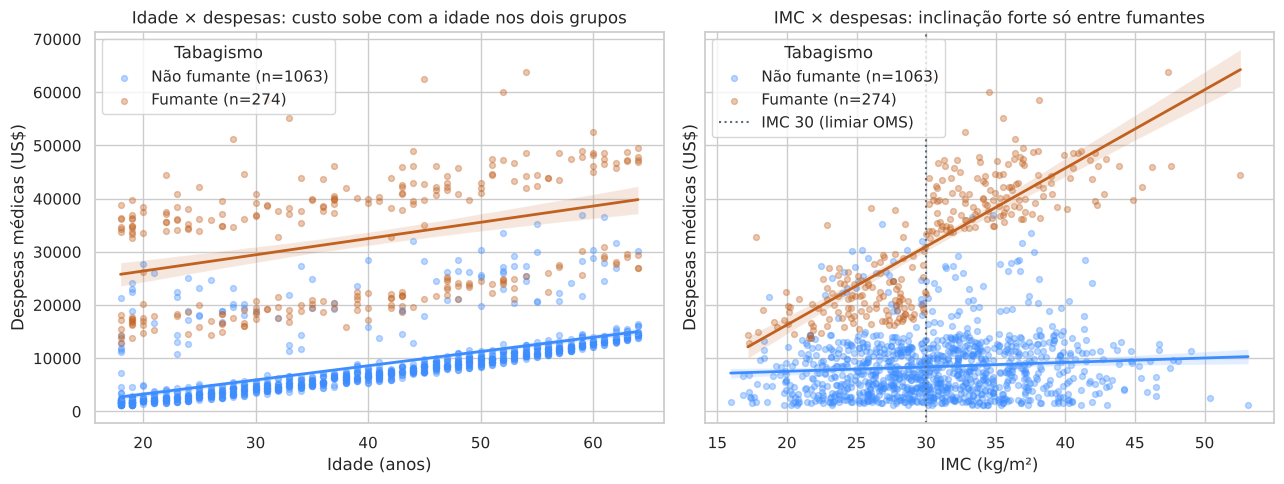

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, variavel, rotulo in [(axes[0], "age", "Idade (anos)"), (axes[1], "bmi", "IMC (kg/m²)")]:
    for grupo in ["no", "yes"]:
        dados = df_eda[df_eda["smoker"] == grupo]
        sns.regplot(data=dados, x=variavel, y="charges", color=CORES_FUMANTE[grupo],
                    scatter_kws={"alpha": 0.35, "s": 18}, line_kws={"linewidth": 2},
                    label=f"{ROTULOS_FUMANTE[grupo]} (n={len(dados)})", ax=ax)
    ax.set(xlabel=rotulo, ylabel="Despesas médicas (US$)")
    ax.legend(title="Tabagismo")
axes[0].set_title("Idade × despesas: custo sobe com a idade nos dois grupos")
axes[1].set_title("IMC × despesas: inclinação forte só entre fumantes")
axes[1].axvline(30, color=CINZA, linestyle=":", linewidth=1.5, label="IMC 30 (limiar OMS)")
axes[1].legend(title="Tabagismo")
plt.tight_layout()
plt.show()

O gráfico de IMC sugere uma mudança de patamar perto de IMC 30 entre fumantes. Para verificar com números, usamos a faixa de obesidade da OMS (IMC ≥ 30) — um **limiar convencional**, escolhido antes de olhar os custos, e não um corte otimizado nos dados. A coluna `obesidade_imc` é auxiliar, criada só em `df_eda`, e deriva de `bmi`, não de `charges`.

In [ ]:
df_eda["obesidade_imc"] = np.where(df_eda["bmi"] >= 30, "IMC >= 30", "IMC < 30")
charges_fumante_imc = (
    df_eda.groupby(["smoker", "obesidade_imc"], observed=True)["charges"]
          .agg(n="count", media="mean", mediana="median", desvio_padrao="std")
          .rename(index=ROTULOS_FUMANTE, level=0)
)
charges_fumante_imc

n     media   mediana  desvio_padrao
smoker      obesidade_imc                                        
Não fumante IMC < 30       502  7,977.03  6,761.62       5,839.23
            IMC >= 30      561  8,855.53  8,083.92       6,102.64
Fumante     IMC < 30       129 21,363.22 20,167.34       5,066.78
            IMC >= 30      145 41,557.99 40,904.20       6,031.47

**Interpretação E.**

- **Base toda:** as três correlações são positivas, mas **fracas**: `age` r = 0,298; `bmi` r = 0,198; `children` r = 0,067 (n = 1.337). Todas têm valor-p < 0,05 (`age` 7,0e-29; `bmi` 2,5e-13; `children` 0,014). Com 1.337 observações, até correlações pequenas ficam "significativas": **significância estatística não é importância prática**. `children` explica quase nada da variação linear de `charges` (r² ≈ 0,005).
- **Separando por tabagismo, o quadro muda:**
  - `age`: r = **0,627** entre não fumantes (n = 1.063) e r = 0,368 entre fumantes (n = 274). O gráfico mostra que a idade eleva o custo nos dois grupos; o r geral (0,298) era fraco porque a enorme diferença entre fumantes e não fumantes "espalha" os pontos verticalmente. Entre não fumantes aparecem faixas paralelas de custo, sinal de outros fatores não registrados na base.
  - `bmi`: r = **0,806** entre fumantes (p = 5,0e-64) e apenas r = 0,084 entre não fumantes (p = 0,006, associação desprezível na prática). A relação IMC–custo é **muito diferente** entre os grupos. A tabela por faixa confirma: entre fumantes, a mediana com IMC ≥ 30 (US$ 40.904,20; n = 145) é cerca do **dobro** da mediana com IMC < 30 (US$ 20.167,34; n = 129); entre não fumantes, as medianas são US$ 8.083,92 e US$ 6.761,62.
  - `children`: r = 0,138 entre não fumantes e r = 0,036 entre fumantes (p = 0,55, sem evidência de correlação linear). Associação fraca em todos os recortes.
- **Leitura:** analisar todos juntos **escondeu** padrões fortes. Esses resultados apontam para uma possível **interação** entre `smoker` e `bmi` (o efeito do IMC depende do tabagismo) — algo que um modelo linear simples, só com termos aditivos, não representa. Isso é uma hipótese para as Partes 3 e 4 avaliarem com validação, não uma conclusão sobre o modelo.
- **Limitações:** Pearson capta só relações lineares; correlação não implica causalidade; os grupos de fumantes têm n menor (274), e o IMC é uma medida grosseira de composição corporal.

## F. Teste qui-quadrado de independência: `smoker` × `sex`

**Motivo da escolha.** Na Seção D, `smoker` foi a variável mais associada a `charges`, e `sex` mostrou uma diferença de médias que poderia ser explicada pela composição dos grupos. Se a proporção de fumantes for diferente entre os sexos, a comparação simples de custos por sexo fica **confundida** pelo tabagismo — e essa informação é relevante para interpretar coeficientes nas Partes 3 e 4. A escolha foi feita pela pergunta, antes de calcular o teste.

- **H₀:** `smoker` e `sex` são independentes (a proporção de fumantes é a mesma nos dois sexos).
- **H₁:** existe associação entre `smoker` e `sex`.
- Nível de significância adotado: α = 0,05.

In [ ]:
tabela_contingencia = pd.crosstab(df_eda["sex"], df_eda["smoker"], margins=True, margins_name="total")
tabela_contingencia

smoker,no,yes,total
sex,,,
female,547,115,662
male,516,159,675
total,1063,274,1337


In [ ]:
proporcao_fumantes = pd.crosstab(df_eda["sex"], df_eda["smoker"], normalize="index").mul(100)
proporcao_fumantes.columns = ["% não fumantes", "% fumantes"]
proporcao_fumantes

,% não fumantes,% fumantes
sex,,
female,82.63,17.37
male,76.44,23.56


In [ ]:
observadas = pd.crosstab(df_eda["sex"], df_eda["smoker"])
chi2, p_value_chi2, graus_liberdade, esperadas = stats.chi2_contingency(observadas)
esperadas_df = pd.DataFrame(esperadas, index=observadas.index, columns=observadas.columns)

print(f"Qui-quadrado (com correção de Yates, padrão do SciPy para tabela 2x2): {chi2:.3f}")
print(f"Graus de liberdade: {graus_liberdade}")
print(f"Valor de p: {p_value_chi2:.4f}")
print(f"Menor frequência esperada: {esperadas_df.min().min():.2f}")
print("Condição (todas as esperadas >= 5):", bool((esperadas_df >= 5).all().all()))
print()
print("Frequências esperadas sob H0:")
print(esperadas_df.round(2))

Qui-quadrado (com correção de Yates, padrão do SciPy para tabela 2x2): 7.469
Graus de liberdade: 1
Valor de p: 0.0063
Menor frequência esperada: 135.67
Condição (todas as esperadas >= 5): True

Frequências esperadas sob H0:
smoker     no    yes
sex                 
female 526.33 135.67
male   536.67 138.33


**Interpretação F.**

- **Resultado:** χ² = 7,469, gl = 1, valor-p = 0,0063. Como p < 0,05, **rejeitamos H₀**: há evidência de associação entre sexo e tabagismo nesta base.
- **Em linguagem simples:** **23,6%** dos homens são fumantes (159 de 675), contra **17,4%** das mulheres (115 de 662). Se as variáveis fossem independentes, esperaríamos cerca de 138 homens fumantes; observamos 159.
- **Condições de aplicação:** a menor frequência esperada é **135,67**, muito acima de 5; a aproximação qui-quadrado é confiável. As observações são pessoas distintas (após a remoção da duplicata). Como a tabela é 2×2, o SciPy aplica a correção de continuidade de Yates, que torna o teste um pouco mais conservador.
- **Consequência para a análise:** a diferença de médias de `charges` por sexo vista na Seção D.3 pode, em parte, refletir a maior proporção de fumantes entre homens — coerente com o fato de que, separando por tabagismo, a diferença por sexo muda de direção.
- **Limitações:** o teste avalia **associação entre categorias**, não causalidade, e **não compara valores monetários de `charges`**. O valor-p não mede a força da associação: a diferença é de cerca de 6 pontos percentuais, moderada na prática. O resultado vale para esta amostra; não sabemos como os dados foram coletados nem se representam alguma população específica.

## Linha de raciocínio: o que parecia, o que verificamos e o que decidimos

Em vários pontos, a primeira leitura dos dados levaria a uma conclusão errada. A tabela resume onde isso aconteceu, que evidência corrigiu a leitura e qual decisão foi tomada. Os números vêm das saídas das Seções C a F.

| # | O que parecia (primeira leitura) | O que verificamos (evidência) | Decisão tomada |
|---|---|---|---|
| 1 | Os **139 pontos** acima do limite 1,5 × IQR pareciam erros a remover. | **136 deles (97,8%) são fumantes**, embora fumantes sejam 20,5% da base (Seção C.1). | **Mantidos.** São um grupo real de custo alto, não erros. Remover apagaria o padrão principal. |
| 2 | `bmi` e `age` pareciam pouco associados ao custo (r = 0,20 e 0,30 na base toda). | Separando por tabagismo: `bmi` r = **0,81** entre fumantes e 0,08 entre não fumantes; `age` r = **0,63** entre não fumantes (Seção E). | Analisar as correlações **por grupo de `smoker`** e registrar a possível interação `bmi × smoker` como hipótese para as Partes 3 e 4. |
| 3 | Homens pareciam ter custo maior (média US$ 1.405 acima). | Medianas praticamente iguais (US$ 9.378 e US$ 9.413); entre não fumantes, mulheres têm média **maior** (Seção D.3). | Testar se a diferença vem da composição: qui-quadrado `smoker × sex`, **p = 0,006**, 23,6% de fumantes entre homens contra 17,4% entre mulheres (Seção F). |
| 4 | `southeast` parecia a região mais cara (maior média). | A maior **mediana** é de `northeast`; a diferença de médias (~US$ 2.400) é pequena diante de desvios de US$ 11 a 14 mil (Seção D.2). | **Não** afirmar diferença regional relevante no custo típico. |

**O que ficou sem resolver (e por quê):**

- **Duplicata sem identificador:** sem coluna de ID, não há como saber se as linhas 195 e 581 são a mesma pessoa ou duas pessoas idênticas. Seguimos a decisão da Parte 1 (remoção); o impacto é de 1 linha em 1.338.
- **EDA feita antes da divisão treino/teste:** os achados orientam hipóteses, mas não devem ser usados para escolher o modelo pelo desempenho. A avaliação real fica com as Partes 3 e 4.
- **Unidade de `charges`:** não documentada; adotamos US$ como suposição explícita.

## G. Dois insights principais

### Insight 1 — Tabagismo é a variável mais associada a despesas médicas altas

- **Afirmação:** fumantes têm despesas médicas muito maiores do que não fumantes, e o tabagismo concentra quase todos os custos extremos da base.
- **Evidência:** mediana de US$ 34.456,35 para fumantes (n = 274) contra US$ 7.345,73 para não fumantes (n = 1.063) — razão de **4,69**; médias de US$ 32.050,23 e US$ 8.440,66 (razão 3,80). Dos **139** registros acima do limite 1,5 × IQR (US$ 34.524,78), **136 (97,8%)** são fumantes, embora fumantes sejam 20,5% da base. No boxplot da Seção D.1, as caixas dos dois grupos praticamente não se sobrepõem. Nenhuma correlação numérica com `charges` na base toda passa de r = 0,30.
- **Interpretação:** `smoker` deve ser a variável de maior peso para explicar `charges`, e a assimetria de `charges` está fortemente ligada a esse grupo. Para a modelagem, isso sugere que erros grandes devem se concentrar nos fumantes de custo alto.
- **Limitação:** dados observacionais: não dá para afirmar que fumar *causa* o aumento, pois fumantes podem diferir em fatores não registrados (histórico de doenças, renda, tipo de plano, hábitos). `smoker` é autodeclarado, sem informação de intensidade ou duração. Os grupos são desiguais (274 contra 1.063), e não sabemos de qual população a amostra foi extraída.

### Insight 2 — A relação entre IMC e despesas depende do tabagismo

- **Afirmação:** o IMC está fortemente associado às despesas **entre fumantes**, mas quase não está entre não fumantes; a correlação geral fraca esconde esse padrão.
- **Evidência:** Pearson IMC × `charges` na base toda: r = 0,198 (n = 1.337). Entre fumantes: **r = 0,806** (n = 274; p = 5,0e-64). Entre não fumantes: **r = 0,084** (n = 1.063; p = 0,006). Entre fumantes, a mediana com IMC ≥ 30 é US$ 40.904,20 (n = 145) contra US$ 20.167,34 com IMC < 30 (n = 129), cerca do dobro; entre não fumantes, US$ 8.083,92 contra US$ 6.761,62. No gráfico de dispersão IMC × despesas (Seção E), a reta dos fumantes é íngreme e a dos não fumantes é quase plana.
- **Interpretação:** há indícios de **interação** entre `smoker` e `bmi`: o "efeito" associado ao IMC muda conforme o tabagismo. Um modelo que trate essas variáveis apenas de forma aditiva pode subestimar custos de fumantes com IMC alto e superestimar os de fumantes com IMC baixo. Vale as Partes 3 e 4 avaliarem, com validação cruzada, se um termo de interação (por exemplo, `bmi × smoker`) melhora o modelo.
- **Limitação:** a evidência é correlacional e vem de um subgrupo de 274 pessoas. O limiar de IMC 30 é convencional (OMS) e serve só para descrição. O IMC não distingue gordura de massa muscular, e a base não registra doenças associadas. A relação observada pode não se repetir em outra população.

## H. Registro das decisões

O `registro_decisoes` segue a convenção do grupo (`variavel`, `acao`, `justificativa`, `impacto_possivel`). Se a Parte 1 já tiver criado o registro, as decisões da EDA são **acrescentadas ao final** sem apagar as anteriores. As linhas abaixo descrevem apenas decisões da Parte 2.

In [ ]:
decisoes_eda = pd.DataFrame([
    {"variavel": "charges",
     "acao": "EDA: descrita com média, mediana, desvio, quartis, assimetria, histograma+KDE e boxplot",
     "justificativa": "Distribuição assimétrica (assimetria ~1,5): média e mediana descrevem coisas diferentes",
     "impacto_possivel": "Partes 3/4 devem esperar erros maiores na cauda de custos altos"},
    {"variavel": "charges",
     "acao": "EDA: possíveis outliers (1,5 x IQR) sinalizados e investigados; nenhum registro excluído",
     "justificativa": "Pontos sinalizados são majoritariamente fumantes: casos legítimos, não erros",
     "impacto_possivel": "Manter a base completa preserva o grupo de maior custo; extremos podem pesar nas métricas"},
    {"variavel": "smoker, region, sex, children",
     "acao": "EDA: comparação de charges por grupo com n, média, mediana, desvio-padrão e boxplot",
     "justificativa": "Comparar centro e dispersão considerando o tamanho dos grupos",
     "impacto_possivel": "Indica smoker como variável de maior associação; region e sex com diferenças pequenas"},
    {"variavel": "age, bmi, children",
     "acao": "EDA: Pearson com valor-p na base toda e separado por smoker; heatmap e dispersão com transparência",
     "justificativa": "Pearson é o método das aulas; separar por smoker evita que a mistura de grupos esconda padrões",
     "impacto_possivel": "Sugere interação bmi x smoker e relação de age em ambos os grupos, a avaliar nos modelos"},
    {"variavel": "obesidade_imc (auxiliar, só em df_eda)",
     "acao": "EDA: faixa IMC >= 30 / < 30 (limiar OMS) usada apenas para descrição",
     "justificativa": "Limiar convencional, definido antes de olhar charges",
     "impacto_possivel": "Não foi adicionada a df_preparado; uso como preditor fica a critério das Partes 3/4"},
    {"variavel": "smoker x sex",
     "acao": "EDA: teste qui-quadrado de independência (scipy, correção de Yates em 2x2)",
     "justificativa": "Verificar se a composição de fumantes difere por sexo e pode confundir comparações de custo",
     "impacto_possivel": "Associação significativa (p < 0,05): diferenças de charges por sexo devem ser lidas com cautela"},
    {"variavel": "df_preparado",
     "acao": "EDA: nenhuma alteração; análises feitas na cópia df_eda; nenhuma coluna criada",
     "justificativa": "Convenção do grupo e prevenção de vazamento de informação do alvo",
     "impacto_possivel": "Partes 3/4 recebem df_preparado exatamente como saiu da Parte 1"},
    {"variavel": "faixa_charges (criada na Parte 1)",
     "acao": "EDA: sinalizada como derivada do alvo e listada em COLUNAS_DERIVADAS_DO_ALVO",
     "justificativa": "É calculada a partir de charges; como preditora, entregaria a resposta ao modelo",
     "impacto_possivel": "Partes 3/4 devem excluí-la dos preditores para evitar vazamento"},
])

if "registro_decisoes" in globals():
    registro_decisoes = pd.concat([registro_decisoes, decisoes_eda], ignore_index=True)
    print("Decisões da EDA acrescentadas ao registro existente da Parte 1.")
else:
    registro_decisoes = decisoes_eda.copy()
    print("Registro da Parte 1 não encontrado nesta execução: criado apenas com decisões da EDA.")

with pd.option_context("display.max_colwidth", None):
    display(registro_decisoes)

Registro da Parte 1 não encontrado nesta execução: criado apenas com decisões da EDA.


,variavel,acao,justificativa,impacto_possivel
0,charges,"EDA: descrita com média, mediana, desvio, quartis, assimetria, histograma+KDE e boxplot","Distribuição assimétrica (assimetria ~1,5): média e mediana descrevem coisas diferentes",Partes 3/4 devem esperar erros maiores na cauda de custos altos
1,charges,"EDA: possíveis outliers (1,5 x IQR) sinalizados e investigados; nenhum registro excluído","Pontos sinalizados são majoritariamente fumantes: casos legítimos, não erros",Manter a base completa preserva o grupo de maior custo; extremos podem pesar nas métricas
2,"smoker, region, sex, children","EDA: comparação de charges por grupo com n, média, mediana, desvio-padrão e boxplot",Comparar centro e dispersão considerando o tamanho dos grupos,Indica smoker como variável de maior associação; region e sex com diferenças pequenas
3,"age, bmi, children",EDA: Pearson com valor-p na base toda e separado por smoker; heatmap e dispersão com transparência,Pearson é o método das aulas; separar por smoker evita que a mistura de grupos esconda padrões,"Sugere interação bmi x smoker e relação de age em ambos os grupos, a avaliar nos modelos"
4,"obesidade_imc (auxiliar, só em df_eda)",EDA: faixa IMC >= 30 / < 30 (limiar OMS) usada apenas para descrição,"Limiar convencional, definido antes de olhar charges",Não foi adicionada a df_preparado; uso como preditor fica a critério das Partes 3/4
5,smoker x sex,"EDA: teste qui-quadrado de independência (scipy, correção de Yates em 2x2)",Verificar se a composição de fumantes difere por sexo e pode confundir comparações de custo,"Associação significativa (p < 0,05): diferenças de charges por sexo devem ser lidas com cautela"
6,df_preparado,EDA: nenhuma alteração; análises feitas na cópia df_eda; nenhuma coluna criada,Convenção do grupo e prevenção de vazamento de informação do alvo,Partes 3/4 recebem df_preparado exatamente como saiu da Parte 1
7,faixa_charges (criada na Parte 1),EDA: sinalizada como derivada do alvo e listada em COLUNAS_DERIVADAS_DO_ALVO,"É calculada a partir de charges; como preditora, entregaria a resposta ao modelo",Partes 3/4 devem excluí-la dos preditores para evitar vazamento


In [ ]:
# Verificações finais de integridade da Parte 2
assert len(df_preparado) == len(df_original) - df_original.duplicated().sum()
assert list(df_preparado.columns) == colunas_recebidas, "a EDA não deve alterar as colunas de df_preparado"
assert all(c in df_preparado.columns for c in COLUNAS_ORIGINAIS), "colunas originais ausentes"
assert "obesidade_imc" not in df_preparado.columns
assert {"variavel", "acao", "justificativa", "impacto_possivel"} <= set(registro_decisoes.columns)
print("OK: df_original e df_preparado preservados; colunas auxiliares só em df_eda.")

OK: df_original e df_preparado preservados; colunas auxiliares só em df_eda.


## I. Fechamento da EDA

- **Padrões mais importantes:** `charges` é fortemente assimétrica à direita (assimetria 1,52; média 41,5% acima da mediana), com uma cauda de custos altos formada quase toda por fumantes.
- **Variáveis mais associadas a `charges`:** `smoker` (mediana 4,69 vezes maior entre fumantes), seguida de `age` (r = 0,30 na base toda e 0,63 entre não fumantes). `bmi` tem associação forte só entre fumantes. `region`, `sex` e `children` mostram diferenças pequenas no custo típico.
- **Relações para investigar na modelagem:** (1) a possível interação `bmi × smoker`; (2) o padrão de `age` em ambos os grupos; (3) a influência da cauda de custos altos sobre os erros. Essas são hipóteses para as Partes 3 e 4 testarem com validação; esta EDA **não** antecipa o desempenho dos modelos.
- **Limitações:** dados observacionais, sem dicionário de dados nem descrição da amostragem; unidade monetária suposta (US$); ausência de variáveis potencialmente relevantes (doenças pré-existentes, tipo de plano, renda); grupos desiguais (274 fumantes, 18–25 pessoas com 4–5 dependentes); Pearson capta apenas relações lineares; e a EDA foi feita na base completa, antes da divisão treino/teste.

# AV2 — Parte 3: Regressão e validação cruzada

**Ciência de Dados — CESMAC | Dataset: custos de seguro médico (`insurance.csv`)**

| Parte | Responsável | Conteúdo |
|---|---|---|
| 1 | Pedro Victhor Monteiro | Importação, diagnóstico, limpeza e preparação |
| 2 | Eduardo Souza de Barros | EDA e insights |
| **3** | **Eduardo Souza de Barros** | **Regressão e validação cruzada (este notebook)** |
| 4 | Eduardo Souza de Barros | Ridge, avaliação final no teste, análise de erros e conclusão |

## A. Objetivo e integração

**Objetivo:** identificar o modelo de regressão linear que tende a prever melhor as despesas médicas (`charges`) de **pessoas novas**.

**Procedimento:**

1. Separamos um **conjunto de teste (20%)**, que fica guardado e **não é usado nesta parte**. Ele só será aberto na Parte 4, depois de o modelo estar escolhido.
2. Comparamos candidatos com **validação cruzada de 5 partes** no treino (`KFold(n_splits=5, shuffle=True, random_state=42)`), **nos mesmos folds**.
3. Métrica: **MAE** (erro absoluto médio, em US$ — unidade suposta, ver Parte 2). O scikit-learn devolve o MAE com sinal negativo (`neg_mean_absolute_error`); multiplicamos por −1.
4. Comparamos também o erro de **treino** com o de **validação** para detectar sobreajuste.

**Integração.** Esta parte recebe `df_preparado` da Parte 1 e cria `X_treino`, `X_teste`, `y_treino`, `y_teste` e `kf`, que a Parte 4 reutiliza para garantir **a mesma divisão e os mesmos folds**.

## 1. Ambiente

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

AZUL = "#3D8DFF"
LARANJA = "#C2611F"
VERDE = "#108A78"
CINZA = "#5F6B7A"

RANDOM_STATE = 42
METRICA = "neg_mean_absolute_error"
COLUNAS_NUMERICAS = ["age", "bmi", "children"]
COLUNAS_CATEGORICAS = ["sex", "smoker", "region"]
COLUNAS_PREDITORAS = COLUNAS_NUMERICAS + COLUNAS_CATEGORICAS
ALVO = "charges"

## 2. Integração e divisão treino/teste

As preditoras são escolhidas **explicitamente**: as seis variáveis originais. Ficam de fora:

- `charges`, que é o alvo;
- `faixa_charges` (Parte 1), que é **calculada a partir do alvo**: usá-la seria entregar a resposta ao modelo (vazamento);
- `age_group` e `bmi_categoria` (Parte 1), que repetem em faixas a informação de `age` e `bmi`, que já entram em escala contínua.

In [ ]:
if "df_preparado" not in globals():
    candidatos = [Path("insurance.csv"), Path("dados/insurance.csv"),
                  Path("../AV2/insurance.csv"), Path("AV2/insurance.csv")]
    caminho = next((p for p in candidatos if p.exists()), None)
    assert caminho is not None, "insurance.csv não encontrado."
    df_original = pd.read_csv(caminho)
    df_preparado = df_original.drop_duplicates().reset_index(drop=True)
    print(f"Execução isolada: {caminho} carregado; duplicata removida (decisão da Parte 1).")

X = df_preparado[COLUNAS_PREDITORAS]
y = df_preparado[ALVO]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

assert not {ALVO, "faixa_charges"} & set(X_treino.columns), "alvo ou derivada do alvo entre as preditoras"
print(f"Treino: {len(X_treino)} pessoas | Teste guardado: {len(X_teste)} pessoas")
print(f"Fumantes no treino: {(X_treino['smoker'] == 'yes').mean():.1%} | no teste: {(X_teste['smoker'] == 'yes').mean():.1%}")

partes = [{"fold": i, "ajuste": len(a), "validacao": len(v)}
          for i, (a, v) in enumerate(kf.split(X_treino), start=1)]
pd.DataFrame(partes).set_index("fold")

Treino: 1069 pessoas | Teste guardado: 268 pessoas
Fumantes no treino: 20.0% | no teste: 22.4%


,ajuste,validacao
fold,,
1,855,214
2,855,214
3,855,214
4,855,214
5,856,213


**Interpretação.** O treino tem **1.069 pessoas** e o teste guardado, **268**. Em cada fold, 855 ou 856 pessoas ajustam o modelo e 213 ou 214 o validam; cada pessoa do treino é validada exatamente uma vez. `shuffle=True` embaralha antes de cortar, e a semente fixa torna a divisão reproduzível. A proporção de fumantes é parecida no treino (20,0%) e no teste (22,4%).

## 3. A variável de interação sugerida pela EDA

Na Parte 2, a correlação entre IMC e despesas foi **r = 0,81 entre fumantes** e **r = 0,08 entre não fumantes**. Uma regressão linear comum dá ao IMC **a mesma inclinação para todos**. Para permitir uma inclinação diferente para fumantes, criamos:

`fumante_x_imc` = `bmi` se a pessoa fuma, **0** se não fuma.

A variável é calculada linha a linha, só com preditoras (não usa `charges` nem aprende nada dos dados), então pode ser criada antes da validação cruzada sem vazamento.

> **Cautela:** a hipótese nasceu de uma EDA feita na base completa. Por isso ela é **testada** aqui com validação cruzada, e não aceita só porque apareceu na EDA.

In [ ]:
def adicionar_interacao(X):
    X = X.copy()
    X["fumante_x_imc"] = np.where(X["smoker"] == "yes", X["bmi"], 0.0)
    return X

X_treino_int = adicionar_interacao(X_treino)
X_treino_int[["bmi", "smoker", "fumante_x_imc"]].head()

,bmi,smoker,fumante_x_imc
1114,24.51,no,0.00
968,25.75,no,0.00
599,37.52,no,0.00
170,41.47,no,0.00
275,26.60,no,0.00


## B. Candidatos comparados nos mesmos 5 folds

| Candidato | Preditoras | Por que entra |
|---|---|---|
| Referência (média) | nenhuma | Piso: sempre prevê a média do treino |
| Simples: idade | `age` | Variável numérica com maior correlação com `charges` (r = 0,30, Parte 2) |
| Simples: tabagismo | `smoker` | Variável mais associada a `charges` na EDA |
| Múltipla | 6 variáveis originais | Usa toda a informação disponível |
| Múltipla + interação | 6 originais + `fumante_x_imc` | Testa a hipótese da EDA |

As categóricas viram colunas 0/1 com `OneHotEncoder(drop="first")` (uma coluna a menos por variável, para evitar redundância), **dentro do `Pipeline`**: em cada fold, as categorias são aprendidas só nas linhas de ajuste. A regressão linear não precisa de padronização; por isso as numéricas entram na escala original, o que deixa os coeficientes em US$ por unidade (Seção C).

`cross_validate(..., return_train_score=True)` devolve o erro de validação **e** o de treino de cada fold.

In [ ]:
def regressao(numericas, categoricas):
    transformadores = []
    if numericas:
        transformadores.append(("num", "passthrough", numericas))
    if categoricas:
        transformadores.append(("cat", OneHotEncoder(drop="first"), categoricas))
    return Pipeline([("preparacao", ColumnTransformer(transformadores)),
                     ("regressao", LinearRegression())])

NUMERICAS_INT = COLUNAS_NUMERICAS + ["fumante_x_imc"]
candidatos = {
    "Referência (média)": (DummyRegressor(strategy="mean"), X_treino),
    "Simples: idade": (regressao(["age"], []), X_treino),
    "Simples: tabagismo": (regressao([], ["smoker"]), X_treino),
    "Múltipla": (regressao(COLUNAS_NUMERICAS, COLUNAS_CATEGORICAS), X_treino),
    "Múltipla + interação": (regressao(NUMERICAS_INT, COLUNAS_CATEGORICAS), X_treino_int),
}

mae_validacao, mae_treino = {}, {}
for nome, (modelo, X_cand) in candidatos.items():
    resultado = cross_validate(modelo, X_cand, y_treino, cv=kf, scoring=METRICA, return_train_score=True)
    mae_validacao[nome] = -resultado["test_score"]
    mae_treino[nome] = -resultado["train_score"]

por_fold = pd.DataFrame(mae_validacao, index=pd.Index(range(1, 6), name="fold"))
resumo_validacao = pd.DataFrame({
    "MAE validação (média)": por_fold.mean(),
    "desvio entre folds": por_fold.std(ddof=0),
    "MAE treino (média)": pd.DataFrame(mae_treino).mean(),
})
resumo_validacao["validação − treino"] = resumo_validacao["MAE validação (média)"] - resumo_validacao["MAE treino (média)"]
display(por_fold.round(0))
resumo_validacao

,Referência (média),Simples: idade,Simples: tabagismo,Múltipla,Múltipla + interação
fold,,,,,
1,"8,514.00","8,496.00","5,472.00","3,873.00","2,930.00"
2,"8,616.00","8,516.00","5,656.00","4,174.00","2,882.00"
3,"9,185.00","9,064.00","5,818.00","4,194.00","2,955.00"
4,"8,583.00","8,949.00","5,282.00","4,468.00","3,238.00"
5,"9,049.00","8,878.00","6,046.00","4,401.00","2,959.00"


,MAE validação (média),desvio entre folds,MAE treino (média),validação − treino
Referência (média),"8,789.32",272.73,"8,786.86",2.46
Simples: idade,"8,780.51",231.95,"8,763.59",16.92
Simples: tabagismo,"5,654.82",265.34,"5,649.19",5.64
Múltipla,"4,221.96",208.55,"4,178.89",43.07
Múltipla + interação,"2,992.73",125.44,"2,966.67",26.06


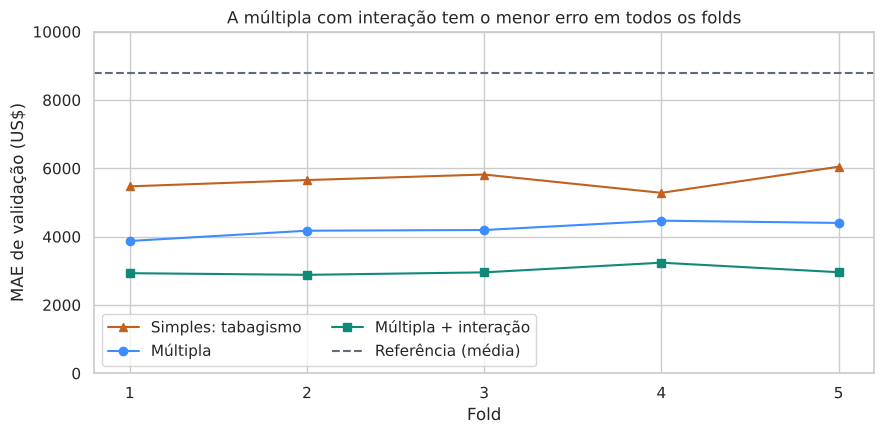

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for nome, cor, marcador in [("Simples: tabagismo", LARANJA, "^"), ("Múltipla", AZUL, "o"),
                            ("Múltipla + interação", VERDE, "s")]:
    ax.plot(por_fold.index, por_fold[nome], marker=marcador, color=cor, label=nome)
ax.axhline(por_fold["Referência (média)"].mean(), color=CINZA, linestyle="--", label="Referência (média)")
ax.set_xticks(por_fold.index)
ax.set(title="A múltipla com interação tem o menor erro em todos os folds",
       xlabel="Fold", ylabel="MAE de validação (US$)")
ax.set_ylim(0, 10_000)
ax.legend(loc="lower left", ncol=2)
plt.tight_layout()
plt.show()

**Interpretação B.**

- **Referência:** prever sempre a média erra, em média, **US$ 8.789**.
- **Simples com idade:** US$ 8.781, praticamente igual à referência. Embora a correlação seja r = 0,30, ela só explica cerca de 9% da variação (r² ≈ 0,09), e a idade sozinha não separa custos baixos de altos. É um bom lembrete de que **correlação "significativa" não garante previsão útil**.
- **Simples com tabagismo:** US$ 5.655 (−36% em relação à referência), com **uma única variável 0/1**. Confirma o Insight 1 da EDA.
- **Múltipla:** US$ 4.222 ± 209. Juntar as seis variáveis reduz o erro à metade em relação à referência.
- **Múltipla + interação:** US$ **2.993 ± 125**, cerca de **29% abaixo** da múltipla, e **em todos os 5 folds** (o pior fold com interação, US$ 3.238, é melhor que o melhor fold sem ela, US$ 3.873). O desvio entre folds também caiu: o resultado é mais estável. **A hipótese da EDA se sustenta na validação.**

**Sobreajuste.** Na múltipla com interação, o MAE de treino (US$ 2.967) e o de validação (US$ 2.993) diferem só em cerca de US$ 26. Um modelo sobreajustado teria treino muito melhor que validação (como o polinômio de grau 8 da Aula 14). Aqui não: o modelo tem poucas variáveis para muitas linhas. Esse dado é importante para a Parte 4, que testa se o Ridge (que combate sobreajuste) traz algum ganho.

## C. O que o melhor modelo linear aprendeu

O modelo é ajustado com as 1.069 pessoas do treino só para **inspecionar os coeficientes** (não é avaliação: o teste continua fechado). As numéricas estão na escala original, então cada coeficiente está em **US$ por unidade**, mantendo as demais variáveis fixas.

In [ ]:
modelo_mult_int = regressao(NUMERICAS_INT, COLUNAS_CATEGORICAS).fit(X_treino_int, y_treino)
coeficientes_parte3 = pd.Series(
    modelo_mult_int.named_steps["regressao"].coef_,
    index=modelo_mult_int.named_steps["preparacao"].get_feature_names_out(),
    name="coeficiente (US$)",
)
intercepto = modelo_mult_int.named_steps["regressao"].intercept_
coef = coeficientes_parte3
print(f"Intercepto: US$ {intercepto:,.2f}")
print(f"Inclinação do IMC | não fumante: US$ {coef['num__bmi']:,.2f} por ponto | "
      f"fumante: US$ {coef['num__bmi'] + coef['num__fumante_x_imc']:,.2f} por ponto")
for imc in [25, 35]:
    efeito = coef["cat__smoker_yes"] + coef["num__fumante_x_imc"] * imc
    print(f"Diferença prevista fumante − não fumante com IMC {imc}: US$ {efeito:,.2f}")
coeficientes_parte3.to_frame()

Intercepto: US$ -1,836.08
Inclinação do IMC | não fumante: US$ 12.49 por ponto | fumante: US$ 1,489.10 por ponto
Diferença prevista fumante − não fumante com IMC 25: US$ 15,227.27
Diferença prevista fumante − não fumante com IMC 35: US$ 29,993.31


,coeficiente (US$)
num__age,259.04
num__bmi,12.49
num__children,570.04
num__fumante_x_imc,"1,476.60"
cat__sex_male,-647.37
cat__smoker_yes,"-21,687.83"
cat__region_northwest,-438.16
cat__region_southeast,-895.67
cat__region_southwest,-884.56


**Interpretação C.**

- **Idade:** cada ano a mais se associa a cerca de **US$ 259** a mais de despesa prevista.
- **Dependentes:** cerca de **US$ 570** por dependente.
- **IMC depende do tabagismo:** para não fumantes, cada ponto de IMC acrescenta só **US$ 12**, praticamente nada. Para fumantes, cerca de **US$ 1.489** por ponto (12 + 1.477).
- **Tabagismo:** o coeficiente de `smoker_yes` (−US$ 21.688) **não deve ser lido sozinho**. Com a interação, ele seria o efeito de fumar com IMC = 0, que não existe na base. O efeito real depende do IMC: a diferença prevista entre fumante e não fumante é de cerca de **US$ 15.227 com IMC 25** e **US$ 29.993 com IMC 35**.
- **Sexo e região:** efeitos de algumas centenas de dólares, pequenos diante dos demais, coerentes com a EDA.

Os coeficientes descrevem **associações** nos dados, não efeitos causais.

## D. Conclusão da Parte 3 e passagem para a Parte 4

- **Melhor candidato linear:** Múltipla + interação, com MAE de validação de US$ 2.993 ± 125, o menor em todos os folds.
- **Sem sinal de sobreajuste:** erro de treino e de validação praticamente iguais.
- **O teste não foi aberto.** A Parte 4 recebe `X_treino`, `X_teste`, `y_treino`, `y_teste` e `kf` desta parte, testa se o **Ridge** melhora o modelo, escolhe o modelo final e o avalia **uma única vez** no teste.

### Linha de raciocínio

| # | Primeira leitura | O que verificamos | Decisão |
|---|---|---|---|
| 1 | A idade, maior correlação numérica (r = 0,30), daria uma boa regressão simples. | MAE de US$ 8.781, quase igual a prever a média (US$ 8.789). | Uma variável correlacionada não basta; seguir para a múltipla. |
| 2 | A múltipla com as seis variáveis seria suficiente. | US$ 4.222, mas a EDA mostrava que a relação IMC × custo muda com o tabagismo. | Testar a interação `fumante_x_imc`. |
| 3 | A interação poderia ser um achado da EDA que não se repete na validação. | −29% de erro, em todos os folds, com desvio menor. | Recomendar Múltipla + interação para a Parte 4. |
| 4 | Mais variáveis poderiam causar sobreajuste. | Treino e validação diferem em ~US$ 26. | Registrar que o Ridge provavelmente terá pouco a corrigir (verificado na Parte 4). |

## E. Registro das decisões

In [ ]:
decisoes_parte3 = pd.DataFrame([
    {"variavel": "divisão treino/teste",
     "acao": "Parte 3: train_test_split 80/20, random_state=42; teste guardado para a Parte 4",
     "justificativa": "Avaliar em pessoas que o modelo nunca viu; parâmetros das aulas",
     "impacto_possivel": "Resultado do teste depende de uma única amostra de 268 pessoas"},
    {"variavel": "preditoras",
     "acao": "Parte 3: age, sex, bmi, children, smoker, region; excluídas charges, faixa_charges, age_group, bmi_categoria",
     "justificativa": "faixa_charges deriva do alvo (vazamento); faixas de idade/IMC repetem age e bmi",
     "impacto_possivel": "Modelo usa só informação disponível para um cliente novo"},
    {"variavel": "validação",
     "acao": "Parte 3: KFold(5, shuffle=True, random_state=42), mesmos folds para todos os candidatos, MAE",
     "justificativa": "Comparação justa entre candidatos sem usar o teste (Aula 14)",
     "impacto_possivel": "Desvio entre folds mostra a estabilidade da comparação"},
    {"variavel": "fumante_x_imc",
     "acao": "Parte 3: interação criada (bmi se fumante, 0 se não) e testada na validação",
     "justificativa": "Hipótese da EDA (r IMC×custo 0,81 em fumantes x 0,08 em não fumantes)",
     "impacto_possivel": "MAE de validação caiu 29% em todos os folds"},
])

if "registro_decisoes" in globals():
    registro_decisoes = pd.concat([registro_decisoes, decisoes_parte3], ignore_index=True)
    print("Decisões da Parte 3 acrescentadas ao registro existente.")
else:
    registro_decisoes = decisoes_parte3.copy()
    print("Registro anterior não encontrado nesta execução: criado só com as decisões da Parte 3.")

with pd.option_context("display.max_colwidth", None):
    display(registro_decisoes)

Decisões da Parte 3 acrescentadas ao registro existente.


,variavel,acao,justificativa,impacto_possivel
0,charges,"EDA: descrita com média, mediana, desvio, quartis, assimetria, histograma+KDE e boxplot","Distribuição assimétrica (assimetria ~1,5): média e mediana descrevem coisas diferentes",Partes 3/4 devem esperar erros maiores na cauda de custos altos
1,charges,"EDA: possíveis outliers (1,5 x IQR) sinalizados e investigados; nenhum registro excluído","Pontos sinalizados são majoritariamente fumantes: casos legítimos, não erros",Manter a base completa preserva o grupo de maior custo; extremos podem pesar nas métricas
2,"smoker, region, sex, children","EDA: comparação de charges por grupo com n, média, mediana, desvio-padrão e boxplot",Comparar centro e dispersão considerando o tamanho dos grupos,Indica smoker como variável de maior associação; region e sex com diferenças pequenas
3,"age, bmi, children",EDA: Pearson com valor-p na base toda e separado por smoker; heatmap e dispersão com transparência,Pearson é o método das aulas; separar por smoker evita que a mistura de grupos esconda padrões,"Sugere interação bmi x smoker e relação de age em ambos os grupos, a avaliar nos modelos"
4,"obesidade_imc (auxiliar, só em df_eda)",EDA: faixa IMC >= 30 / < 30 (limiar OMS) usada apenas para descrição,"Limiar convencional, definido antes de olhar charges",Não foi adicionada a df_preparado; uso como preditor fica a critério das Partes 3/4
5,smoker x sex,"EDA: teste qui-quadrado de independência (scipy, correção de Yates em 2x2)",Verificar se a composição de fumantes difere por sexo e pode confundir comparações de custo,"Associação significativa (p < 0,05): diferenças de charges por sexo devem ser lidas com cautela"
6,df_preparado,EDA: nenhuma alteração; análises feitas na cópia df_eda; nenhuma coluna criada,Convenção do grupo e prevenção de vazamento de informação do alvo,Partes 3/4 recebem df_preparado exatamente como saiu da Parte 1
7,faixa_charges (criada na Parte 1),EDA: sinalizada como derivada do alvo e listada em COLUNAS_DERIVADAS_DO_ALVO,"É calculada a partir de charges; como preditora, entregaria a resposta ao modelo",Partes 3/4 devem excluí-la dos preditores para evitar vazamento
8,divisão treino/teste,"Parte 3: train_test_split 80/20, random_state=42; teste guardado para a Parte 4",Avaliar em pessoas que o modelo nunca viu; parâmetros das aulas,Resultado do teste depende de uma única amostra de 268 pessoas
9,preditoras,"Parte 3: age, sex, bmi, children, smoker, region; excluídas charges, faixa_charges, age_group, bmi_categoria",faixa_charges deriva do alvo (vazamento); faixas de idade/IMC repetem age e bmi,Modelo usa só informação disponível para um cliente novo


# AV2 — Parte 4: Ridge, avaliação final no teste, análise de erros e conclusão

**Ciência de Dados — CESMAC | Dataset: custos de seguro médico (`insurance.csv`)**

| Parte | Responsável | Conteúdo |
|---|---|---|
| 1 | Pedro Victhor Monteiro | Importação, diagnóstico, limpeza e preparação |
| 2 | Eduardo Souza de Barros | EDA e insights |
| 3 | Eduardo Souza de Barros | Regressão e validação cruzada |
| **4** | **Eduardo Souza de Barros** | **Ridge, avaliação final no teste, análise de erros e conclusão (este notebook)** |

## A. Objetivo e integração

**Objetivos desta parte:**

1. Verificar se a penalização do **Ridge** melhora os modelos lineares da Parte 3 (com e sem a interação `fumante_x_imc`).
2. Escolher o modelo final **apenas com o treino** e medir seu desempenho em pessoas que ele nunca viu (**conjunto de teste**).
3. Identificar **onde** o modelo erra mais e o que isso revela sobre as limitações da análise.

**Procedimento:**

- A escolha do modelo e do α usa **somente o treino**, com validação cruzada de 5 partes (`KFold(n_splits=5, shuffle=True, random_state=42)`) e os **mesmos folds** para todos os candidatos.
- Toda transformação que aprende algo com os dados (`StandardScaler`, `OneHotEncoder`) fica **dentro do `Pipeline`**, para ser ajustada só nas linhas de ajuste de cada fold.
- O **teste é aberto uma única vez**, depois de a decisão estar registrada, e só para o modelo escolhido.
- Métrica principal: **MAE** (erro absoluto médio, em US$ — unidade suposta, ver Parte 2). No teste, também RMSE e R².

**Integração.** No notebook único, a célula de integração reutiliza `df_preparado` (Parte 1) e, se a Parte 3 já tiver criado `X_treino`, `X_teste`, `y_treino`, `y_teste` e `kf`, usa **a mesma divisão e os mesmos folds**. Executado sozinho, o notebook recria tudo com os parâmetros das aulas (`test_size=0.20`, `random_state=42`).

## 1. Ambiente

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

AZUL = "#3D8DFF"
LARANJA = "#C2611F"
VERDE = "#108A78"
VERMELHO = "#D05D52"
CINZA = "#5F6B7A"
CORES_FUMANTE = {"no": AZUL, "yes": LARANJA}
ROTULOS_FUMANTE = {"no": "Não fumante", "yes": "Fumante"}

RANDOM_STATE = 42
METRICA = "neg_mean_absolute_error"
ALPHAS = np.logspace(-3, 3, 13)  # mesma grade da Aula 16

COLUNAS_NUMERICAS = ["age", "bmi", "children"]
COLUNAS_CATEGORICAS = ["sex", "smoker", "region"]
COLUNAS_PREDITORAS = COLUNAS_NUMERICAS + COLUNAS_CATEGORICAS
ALVO = "charges"

## 2. Integração com as Partes 1 e 3

- Se `df_preparado` não existir (execução isolada), o CSV é carregado e só a decisão da Parte 1 sobre a duplicata é reproduzida.
- Se a Parte 3 já tiver feito a divisão, ela é reutilizada, desde que contenha as colunas originais. Caso contrário, a divisão é recriada com os parâmetros das aulas.
- As preditoras são escolhidas **explicitamente**. Assim, `charges` e colunas derivadas dele (como `faixa_charges`, da Parte 1) **nunca** entram no modelo.

In [ ]:
if "df_preparado" not in globals():
    candidatos = [Path("insurance.csv"), Path("dados/insurance.csv"),
                  Path("../AV2/insurance.csv"), Path("AV2/insurance.csv")]
    caminho = next((p for p in candidatos if p.exists()), None)
    assert caminho is not None, "insurance.csv não encontrado."
    df_original = pd.read_csv(caminho)
    df_preparado = df_original.drop_duplicates().reset_index(drop=True)
    print(f"Execução isolada: {caminho} carregado; duplicata removida (decisão da Parte 1).")

variaveis_parte3 = ["X_treino", "X_teste", "y_treino", "y_teste"]
parte3_disponivel = all(v in globals() for v in variaveis_parte3) and set(COLUNAS_PREDITORAS) <= set(X_treino.columns)

if parte3_disponivel:
    origem_divisao = "Parte 3 (mesma divisão e mesmos folds)"
    X_treino_p4 = X_treino[COLUNAS_PREDITORAS].copy()
    X_teste_p4 = X_teste[COLUNAS_PREDITORAS].copy()
    y_treino_p4, y_teste_p4 = y_treino.copy(), y_teste.copy()
else:
    origem_divisao = "recriada nesta parte (test_size=0.20, random_state=42)"
    X_treino_p4, X_teste_p4, y_treino_p4, y_teste_p4 = train_test_split(
        df_preparado[COLUNAS_PREDITORAS], df_preparado[ALVO],
        test_size=0.20, random_state=RANDOM_STATE,
    )

kf_p4 = kf if "kf" in globals() else KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

colunas_proibidas = {ALVO, "faixa_charges"}
assert not colunas_proibidas & set(X_treino_p4.columns), "alvo ou coluna derivada do alvo entre as preditoras"
assert y_treino_p4.name == ALVO

print("Divisão:", origem_divisao)
print(f"Treino: {len(X_treino_p4)} pessoas | Teste guardado: {len(X_teste_p4)} pessoas")
print(f"Fumantes no treino: {(X_treino_p4['smoker'] == 'yes').mean():.1%} | no teste: {(X_teste_p4['smoker'] == 'yes').mean():.1%}")
print("Preditoras:", COLUNAS_PREDITORAS)

Divisão: Parte 3 (mesma divisão e mesmos folds)
Treino: 1069 pessoas | Teste guardado: 268 pessoas
Fumantes no treino: 20.0% | no teste: 22.4%
Preditoras: ['age', 'bmi', 'children', 'sex', 'smoker', 'region']


**Interpretação.** O treino tem **1.069 pessoas** e o teste guardado, **268** (80/20). Em cada rodada da validação cruzada, cerca de 855 pessoas ajustam o modelo e 214 o validam. A proporção de fumantes é parecida nos dois conjuntos (20,0% no treino e 22,4% no teste), então o teste não está muito desequilibrado em relação à variável mais importante da EDA.

**Preditoras usadas:** as seis variáveis originais. `charges` é o alvo. `faixa_charges` foi excluída porque é calculada a partir do alvo (vazamento). `age_group` e `bmi_categoria` foram deixadas de fora porque repetem, em faixas, a informação de `age` e `bmi`, que já entram em escala contínua.

## B. Variável de interação (vinda da Parte 3)

A Parte 3 mostrou que a interação `fumante_x_imc` (= `bmi` se a pessoa fuma, 0 se não fuma) reduz o MAE de validação da regressão múltipla em cerca de 29%. Ela é redefinida aqui com a mesma regra, para que este notebook também rode sozinho. A variável é calculada linha a linha, só com preditoras, sem vazamento.

In [ ]:
def adicionar_interacao(X):
    X = X.copy()
    X["fumante_x_imc"] = np.where(X["smoker"] == "yes", X["bmi"], 0.0)
    return X

X_treino_int = adicionar_interacao(X_treino_p4)
X_teste_int = adicionar_interacao(X_teste_p4)
X_treino_int.head()

,age,bmi,children,sex,smoker,region,fumante_x_imc
1114,23,24.51,0,male,no,northeast,0.00
968,21,25.75,2,male,no,northeast,0.00
599,52,37.52,2,female,no,northwest,0.00
170,63,41.47,0,male,no,southeast,0.00
275,47,26.60,2,female,no,northeast,0.00


## C. Candidatos comparados nos mesmos 5 folds

| Candidato | Preditoras | Por que entra |
|---|---|---|
| Linear | 6 originais | Regressão múltipla da Parte 3 (referência para o Ridge) |
| Ridge | 6 originais | Testa se a penalização melhora a linear |
| Linear + interação | 6 originais + `fumante_x_imc` | Melhor modelo linear da Parte 3 |
| Ridge + interação | 6 originais + `fumante_x_imc` | Testa a penalização no melhor modelo linear |

Em todos os modelos: numéricas padronizadas (`StandardScaler`) e categóricas em *one-hot* (`OneHotEncoder(drop="first")`, uma coluna a menos por variável para evitar redundância), **dentro do `Pipeline`**. O Ridge **exige** a padronização: a penalidade soma os quadrados dos coeficientes, e eles só são comparáveis se as variáveis estiverem na mesma escala.

In [ ]:
def criar_preparacao(numericas):
    return ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(drop="first"), COLUNAS_CATEGORICAS),
    ])

NUMERICAS_INT = COLUNAS_NUMERICAS + ["fumante_x_imc"]

def pipeline_linear(numericas):
    return Pipeline([("preparacao", criar_preparacao(numericas)), ("regressao", LinearRegression())])

def pipeline_ridge(numericas, alpha=1.0):
    return Pipeline([("preparacao", criar_preparacao(numericas)), ("ridge", Ridge(alpha=alpha))])

def mae_cv(modelo, X):
    return -cross_val_score(modelo, X, y_treino_p4, cv=kf_p4, scoring=METRICA)

### C.1 Escolha de α para o Ridge (somente treino)

Para cada versão (sem e com interação), testamos 13 valores de α (de 0,001 a 1.000) com `GridSearchCV`, nos mesmos folds. α pequeno ≈ quase sem penalização (próximo da regressão linear); α grande = coeficientes fortemente "encolhidos".

In [ ]:
busca_ridge = GridSearchCV(pipeline_ridge(COLUNAS_NUMERICAS), {"ridge__alpha": ALPHAS},
                           cv=kf_p4, scoring=METRICA).fit(X_treino_p4, y_treino_p4)
busca_ridge_int = GridSearchCV(pipeline_ridge(NUMERICAS_INT), {"ridge__alpha": ALPHAS},
                               cv=kf_p4, scoring=METRICA).fit(X_treino_int, y_treino_p4)

def tabela_grade(busca):
    r = pd.DataFrame(busca.cv_results_)
    notas = -r[[f"split{i}_test_score" for i in range(5)]].to_numpy()
    return pd.DataFrame({"MAE médio": notas.mean(axis=1), "desvio": notas.std(axis=1)},
                        index=pd.Index([f"{a:g}" for a in ALPHAS], name="alpha"))

grade_ridge = tabela_grade(busca_ridge)
grade_ridge_int = tabela_grade(busca_ridge_int)
alpha_ridge = busca_ridge.best_params_["ridge__alpha"]
alpha_ridge_int = busca_ridge_int.best_params_["ridge__alpha"]

print(f"Ridge sem interação: melhor α = {alpha_ridge:g} | MAE médio = US$ {-busca_ridge.best_score_:,.2f}")
print(f"Ridge com interação: melhor α = {alpha_ridge_int:g} | MAE médio = US$ {-busca_ridge_int.best_score_:,.2f}")
pd.concat({"sem interação": grade_ridge, "com interação": grade_ridge_int}, axis=1)

Ridge sem interação: melhor α = 0.001 | MAE médio = US$ 4,221.97
Ridge com interação: melhor α = 0.1 | MAE médio = US$ 2,992.12


sem interação        com interação       
               MAE médio desvio     MAE médio desvio
alpha                                               
0.001           4,221.97 208.55      2,992.72 125.46
0.00316228      4,222.00 208.54      2,992.71 125.50
0.01            4,222.06 208.52      2,992.66 125.62
0.0316228       4,222.28 208.46      2,992.50 126.00
0.1             4,222.98 208.27      2,992.12 127.15
0.316228        4,225.17 207.67      2,992.41 130.00
1               4,232.15 205.78      3,000.29 136.06
3.16228         4,254.48 200.17      3,045.63 146.47
10              4,328.13 187.18      3,177.69 145.86
31.6228         4,571.84 171.12      3,354.02 145.59
100             5,244.35 184.25      3,625.95 137.52
316.228         6,736.06 213.30      4,245.03 138.52
1000            7,917.13 242.49      5,513.45 193.99

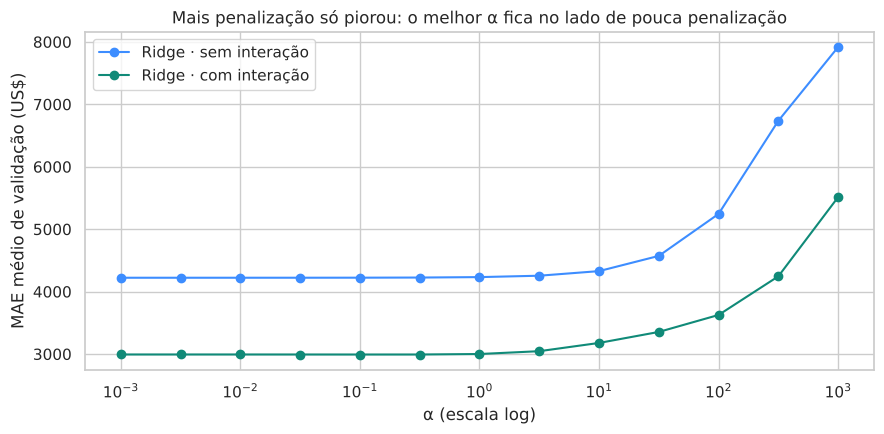

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ALPHAS, grade_ridge["MAE médio"], "o-", color=AZUL, label="Ridge · sem interação")
ax.plot(ALPHAS, grade_ridge_int["MAE médio"], "o-", color=VERDE, label="Ridge · com interação")
ax.set(xscale="log", xlabel="α (escala log)", ylabel="MAE médio de validação (US$)",
       title="Mais penalização só piorou: o melhor α fica no lado de pouca penalização")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação C.1.**

- **Sem interação**, o menor MAE médio (US$ 4.221,97) ocorreu em **α = 0,001, a ponta inferior da grade**. A curva é praticamente plana até α ≈ 1 e depois só sobe. Um mínimo na ponta inferior não pede uma grade maior: estender para α ainda menor só aproximaria o modelo da regressão linear comum (α → 0), que é o que ele já é. Ou seja: **a penalização não ajuda**.
- **Com interação**, o melhor foi **α = 0,1** (US$ 2.992,12), mas a diferença para α = 0,001 é de **menos de US$ 1** (US$ 2.992,7). É uma curva plana, não um mínimo nítido.
- **Motivo:** o Ridge combate o **sobreajuste**, comum quando há muitas variáveis para poucas linhas (como o polinômio de grau 8 da Aula 16). Aqui há 6–7 variáveis para cerca de 855 linhas por fold: o modelo linear já é simples demais para sobreajustar. O problema dele é outro (falta de forma), como mostra a próxima tabela.

### C.2 Comparação dos cinco candidatos, fold a fold

In [ ]:
candidatos_cv = {
    "Linear": (pipeline_linear(COLUNAS_NUMERICAS), X_treino_p4),
    f"Ridge (α={alpha_ridge:g})": (pipeline_ridge(COLUNAS_NUMERICAS, alpha_ridge), X_treino_p4),
    "Linear + interação": (pipeline_linear(NUMERICAS_INT), X_treino_int),
    f"Ridge + interação (α={alpha_ridge_int:g})": (pipeline_ridge(NUMERICAS_INT, alpha_ridge_int), X_treino_int),
}
notas_cv = {nome: mae_cv(modelo, X) for nome, (modelo, X) in candidatos_cv.items()}

por_fold = pd.DataFrame(notas_cv, index=pd.Index(range(1, 6), name="fold"))
resumo_cv = pd.DataFrame({
    "MAE médio": por_fold.mean(),
    "desvio": por_fold.std(ddof=0),
}).sort_values("MAE médio")
display(por_fold.round(0))
resumo_cv

,Linear,Ridge (α=0.001),Linear + interação,Ridge + interação (α=0.1)
fold,,,,
1,"3,873.00","3,873.00","2,930.00","2,925.00"
2,"4,174.00","4,174.00","2,882.00","2,884.00"
3,"4,194.00","4,194.00","2,955.00","2,954.00"
4,"4,468.00","4,468.00","3,238.00","3,241.00"
5,"4,401.00","4,401.00","2,959.00","2,958.00"


,MAE médio,desvio
Ridge + interação (α=0.1),"2,992.12",127.15
Linear + interação,"2,992.73",125.44
Linear,"4,221.96",208.55
Ridge (α=0.001),"4,221.97",208.55


**Interpretação C.2.**

- Os modelos lineares reproduzem exatamente os resultados da Parte 3 (mesmos folds): **Linear** US$ 4.222 ± 209 e **Linear + interação** US$ 2.993 ± 125.
- **Ridge sem interação:** US$ 4.222, idêntico à Linear (α ≈ 0).
- **Ridge + interação:** US$ 2.992 ± 127, praticamente igual à Linear + interação (diferença menor que US$ 1).
- Em ambos os casos, o ganho do modelo veio da **interação** (Parte 3), não da **penalização**.

## D. Ridge × regressão linear no modelo com interação

Comparamos os erros **na mesma ordem dos folds**: `Linear − Ridge` positivo favorece o Ridge.

In [ ]:
nome_ridge_int = f"Ridge + interação (α={alpha_ridge_int:g})"
comparacao_folds = pd.DataFrame({
    "Linear + interação": por_fold["Linear + interação"],
    "Ridge + interação": por_fold[nome_ridge_int],
})
comparacao_folds["ganho_Ridge"] = comparacao_folds["Linear + interação"] - comparacao_folds["Ridge + interação"]
print(f"Vitórias do Ridge: {(comparacao_folds['ganho_Ridge'] > 0).sum()} de 5")
print(f"Ganho médio do Ridge: US$ {comparacao_folds['ganho_Ridge'].mean():,.2f}")
comparacao_folds

Vitórias do Ridge: 3 de 5
Ganho médio do Ridge: US$ 0.61


,Linear + interação,Ridge + interação,ganho_Ridge
fold,,,
1,"2,930.30","2,924.66",5.64
2,"2,881.93","2,883.68",-1.75
3,"2,954.61","2,953.66",0.95
4,"3,237.53","3,240.84",-3.31
5,"2,959.27","2,957.75",1.52


Os coeficientes padronizados mostram **quanto** o Ridge encolheu o modelo (ajustados nos 1.069 do treino; inspeção, não avaliação no teste).

In [ ]:
linear_int_treino = pipeline_linear(NUMERICAS_INT).fit(X_treino_int, y_treino_p4)
ridge_int_treino = pipeline_ridge(NUMERICAS_INT, alpha_ridge_int).fit(X_treino_int, y_treino_p4)
nomes_coef = linear_int_treino.named_steps["preparacao"].get_feature_names_out()

coeficientes = pd.DataFrame({
    "Linear": linear_int_treino.named_steps["regressao"].coef_,
    "Ridge": ridge_int_treino.named_steps["ridge"].coef_,
}, index=nomes_coef)
coeficientes["diferença"] = coeficientes["Ridge"] - coeficientes["Linear"]
soma_quadrados = (coeficientes[["Linear", "Ridge"]] ** 2).sum()
print(f"Soma dos quadrados dos coeficientes | Linear: {soma_quadrados['Linear']:,.0f} | "
      f"Ridge: {soma_quadrados['Ridge']:,.0f} ({soma_quadrados['Ridge'] / soma_quadrados['Linear'] - 1:.1%})")
coeficientes

Soma dos quadrados dos coeficientes | Linear: 823,086,276 | Ridge: 798,479,507 (-3.0%)


,Linear,Ridge,diferença
num__age,"3,624.56","3,622.98",-1.57
num__bmi,75.56,92.89,17.32
num__children,680.72,680.16,-0.56
num__fumante_x_imc,"18,355.44","18,185.28",-170.16
cat__sex_male,-647.37,-642.92,4.45
cat__smoker_yes,"-21,687.83","-21,260.25",427.58
cat__region_northwest,-438.16,-436.11,2.05
cat__region_southeast,-895.67,-894.60,1.07
cat__region_southwest,-884.56,-880.87,3.69


**Interpretação D.** O Ridge venceu em 3 dos 5 folds e perdeu nos outros 2, com ganho médio de **US$ 0,61**, muito abaixo da oscilação entre folds (desvio de ~US$ 125). A soma dos quadrados dos coeficientes caiu cerca de 3%: a penalidade agiu, mas encolheu pouco porque o α escolhido é pequeno, e isso não se converteu em previsões melhores. **Não há evidência de que o Ridge melhore este modelo.** Isso não é uma falha do Ridge: ele resolve sobreajuste, e este modelo não sofre de sobreajuste.

## E. Decisão registrada **antes** de abrir o teste

**Modelo escolhido: Linear + interação** (regressão linear com as 6 variáveis originais e `fumante_x_imc`).

**Justificativa:**

1. A interação reduziu o MAE de validação de US$ 4.222 ± 209 para **US$ 2.993 ± 125**, em todos os 5 folds.
2. O Ridge com interação ficou empatado (US$ 2.992 ± 127): diferença menor que US$ 1, com o sinal mudando entre folds. Pelo critério da Aula 14, **em empate dentro da oscilação entre folds, a opção mais simples merece preferência**. A regressão linear não tem o hiperparâmetro α para escolher.
3. Todas as variáveis do modelo são conhecidas **no momento da previsão** (idade, sexo, IMC, dependentes, tabagismo e região de um novo cliente).

O teste será aberto **uma única vez**, para este modelo. Se o resultado for pior que o esperado, **não** voltaremos a trocar variáveis com base nele: isso transformaria o teste em validação e tornaria a estimativa otimista.

In [ ]:
nome_escolhido = "Linear + interação"
melhor_media = resumo_cv["MAE médio"].min()
diferenca_para_melhor = resumo_cv.loc[nome_escolhido, "MAE médio"] - melhor_media
oscilacao = resumo_cv.loc[nome_escolhido, "desvio"]
print(f"Escolhido: {nome_escolhido} | diferença para o menor MAE médio: US$ {diferenca_para_melhor:,.2f} "
      f"| desvio entre folds: US$ {oscilacao:,.2f}")
if diferenca_para_melhor > oscilacao:
    print("ATENÇÃO: a diferença para o melhor candidato supera a oscilação; revise a decisão acima.")

Escolhido: Linear + interação | diferença para o menor MAE médio: US$ 0.61 | desvio entre folds: US$ 125.44


## F. Avaliação final no conjunto de teste

O modelo escolhido é reajustado com as **1.069 pessoas do treino** e avaliado **uma vez** nas 268 do teste.

In [ ]:
modelo_final = pipeline_linear(NUMERICAS_INT).fit(X_treino_int, y_treino_p4)
previsoes_teste = modelo_final.predict(X_teste_int)

mae_teste = mean_absolute_error(y_teste_p4, previsoes_teste)
rmse_teste = np.sqrt(mean_squared_error(y_teste_p4, previsoes_teste))
r2_teste = r2_score(y_teste_p4, previsoes_teste)
mae_validacao = resumo_cv.loc[nome_escolhido, "MAE médio"]

metricas_teste = pd.DataFrame({
    "valor": [mae_teste, rmse_teste, r2_teste, mae_validacao],
}, index=["MAE no teste (US$)", "RMSE no teste (US$)", "R² no teste", "MAE médio na validação (US$)"])
print(f"MAE: US$ {mae_teste:,.2f} | RMSE: US$ {rmse_teste:,.2f} | R²: {r2_teste:.3f}")
print(f"Mediana de charges no teste: US$ {y_teste_p4.median():,.2f}")
print(f"Menor previsão: US$ {previsoes_teste.min():,.2f} (nenhuma previsão negativa: {bool((previsoes_teste > 0).all())})")
metricas_teste

MAE: US$ 2,828.97 | RMSE: US$ 4,572.81 | R²: 0.886
Mediana de charges no teste: US$ 9,535.65
Menor previsão: US$ 1,660.18 (nenhuma previsão negativa: True)


,valor
MAE no teste (US$),"2,828.97"
RMSE no teste (US$),"4,572.81"
R² no teste,0.89
MAE médio na validação (US$),"2,992.73"


**Interpretação F.**

- **MAE = US$ 2.828,97:** em média, a previsão erra o custo de uma pessoa nova em cerca de US$ 2,8 mil, para mais ou para menos. Ficou **próximo do MAE médio de validação** (US$ 2.992,72), um pouco abaixo. Isso indica que a validação cruzada deu uma estimativa coerente; a diferença está dentro do que se espera de uma única amostra de 268 pessoas (outro sorteio do teste daria outro número).
- **RMSE = US$ 4.572,81**, bem maior que o MAE. O RMSE eleva os erros ao quadrado antes da média, então pesa mais os **erros grandes**: a distância entre RMSE e MAE indica que existem alguns erros muito maiores que o típico (investigados na Seção G).
- **R² = 0,886:** o modelo explica cerca de 89% da variação de `charges` no teste, em comparação com prever sempre a média.
- **Escala:** o MAE (US$ 2,8 mil) não é pequeno diante da mediana dos custos (US$ 9.535,65 no teste). O modelo distingue bem perfis de custo baixo e alto, mas a previsão individual ainda tem incerteza considerável.

## G. Análise de erros

**Objetivo:** verificar se os erros se distribuem ao acaso ou se o modelo erra de forma sistemática em algum grupo.

Convenção: **erro = observado − previsto**. Erro positivo = o modelo **subestimou** o custo; negativo = **superestimou**. As faixas de custo observado abaixo são usadas **só para descrever** os erros depois das previsões (como na Aula 14); não entram no modelo.

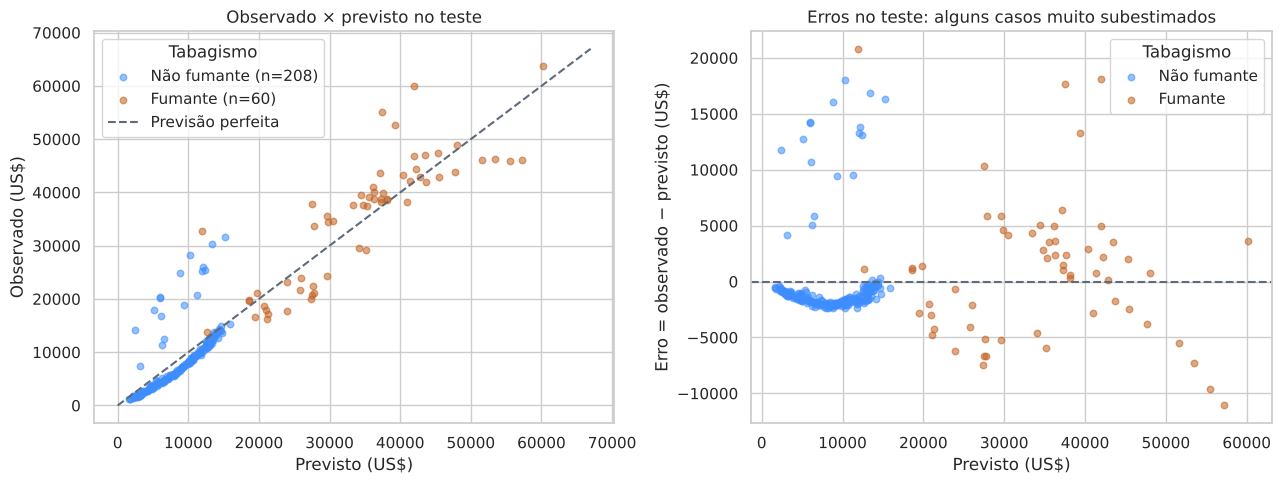

In [ ]:
erros_teste = X_teste_p4.copy()
erros_teste["observado"] = y_teste_p4
erros_teste["previsto"] = previsoes_teste
erros_teste["erro"] = erros_teste["observado"] - erros_teste["previsto"]
erros_teste["erro_absoluto"] = erros_teste["erro"].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for grupo in ["no", "yes"]:
    dados = erros_teste[erros_teste["smoker"] == grupo]
    axes[0].scatter(dados["previsto"], dados["observado"], alpha=0.55, s=22,
                    color=CORES_FUMANTE[grupo], label=f"{ROTULOS_FUMANTE[grupo]} (n={len(dados)})")
    axes[1].scatter(dados["previsto"], dados["erro"], alpha=0.55, s=22,
                    color=CORES_FUMANTE[grupo], label=ROTULOS_FUMANTE[grupo])
limite = erros_teste[["previsto", "observado"]].max().max() * 1.05
axes[0].plot([0, limite], [0, limite], color=CINZA, linestyle="--", linewidth=1.5, label="Previsão perfeita")
axes[0].set(title="Observado × previsto no teste", xlabel="Previsto (US$)", ylabel="Observado (US$)")
axes[1].axhline(0, color=CINZA, linestyle="--", linewidth=1.5)
axes[1].set(title="Erros no teste: alguns casos muito subestimados",
            xlabel="Previsto (US$)", ylabel="Erro = observado − previsto (US$)")
for ax in axes:
    ax.legend(title="Tabagismo")
plt.tight_layout()
plt.show()

In [ ]:
erros_teste["faixa_imc"] = np.where(erros_teste["bmi"] >= 30, "IMC >= 30", "IMC < 30")
erros_por_grupo = (
    erros_teste.groupby(["smoker", "faixa_imc"])
               .agg(n=("erro", "size"), MAE=("erro_absoluto", "mean"), erro_medio=("erro", "mean"))
               .rename(index=ROTULOS_FUMANTE, level=0)
)
erros_por_grupo

n      MAE  erro_medio
smoker      faixa_imc                          
Não fumante IMC < 30    93 2,304.46     -265.92
            IMC >= 30  115 2,265.47     -336.11
Fumante     IMC < 30    22 4,889.91   -1,623.45
            IMC >= 30   38 4,624.84    2,294.96

In [ ]:
erros_teste["faixa_observada"] = pd.cut(erros_teste["observado"], [0, 10_000, 30_000, np.inf],
                                        labels=["até 10 mil", "10 a 30 mil", "acima de 30 mil"])
erros_por_faixa = (
    erros_teste.groupby("faixa_observada", observed=True)
               .agg(n=("erro", "size"), MAE=("erro_absoluto", "mean"), erro_medio=("erro", "mean"))
)
maiores_10pct = erros_teste["erro_absoluto"].nlargest(int(len(erros_teste) * 0.10))
print(f"Erros absolutos acima de US$ 10 mil: {(erros_teste['erro_absoluto'] > 10_000).sum()} de {len(erros_teste)}")
print(f"Mediana do erro absoluto: US$ {erros_teste['erro_absoluto'].median():,.2f}")
print(f"Os 10% maiores erros ({len(maiores_10pct)} casos) somam "
      f"{maiores_10pct.sum() / erros_teste['erro_absoluto'].sum():.1%} de todo o erro absoluto")
erros_por_faixa

Erros absolutos acima de US$ 10 mil: 18 de 268
Mediana do erro absoluto: US$ 1,731.96
Os 10% maiores erros (26 casos) somam 42.9% de todo o erro absoluto


,n,MAE,erro_medio
faixa_observada,,,
até 10 mil,142,"1,593.13","-1,534.92"
10 a 30 mil,84,"3,474.12",648.67
acima de 30 mil,42,"5,717.02","3,609.04"


In [ ]:
erros_teste.nlargest(6, "erro_absoluto")[
    ["observado", "previsto", "erro", "age", "bmi", "smoker", "children", "region"]
].round(0)

,observado,previsto,erro,age,bmi,smoker,children,region
128,"32,734.00","11,921.00","20,813.00",32,18.00,yes,2,northwest
1230,"60,021.00","41,922.00","18,099.00",52,34.00,yes,3,northwest
987,"28,340.00","10,298.00","18,042.00",45,28.00,no,1,northwest
819,"55,135.00","37,494.00","17,641.00",33,36.00,yes,0,northwest
115,"30,260.00","13,416.00","16,844.00",60,29.00,no,0,northeast
573,"31,620.00","15,255.00","16,365.00",62,37.00,no,1,northeast


**Interpretação G.**

1. **Os erros se concentram em poucos casos.** A mediana do erro absoluto é US$ 1.732, bem abaixo do MAE (US$ 2.829); 18 das 268 pessoas (6,7%) têm erro acima de US$ 10 mil, e os 10% maiores erros (26 casos) respondem por **42,9%** de todo o erro absoluto. É por isso que o RMSE é tão maior que o MAE.
2. **Fumantes são mais difíceis de prever:** MAE em torno de US$ 4,6–4,9 mil, contra cerca de US$ 2,3 mil nos não fumantes.
3. **Há um erro sistemático entre fumantes, ligado ao limiar de IMC 30.** Para fumantes com IMC < 30, o erro médio é **−US$ 1.623** (o modelo **superestima**); para fumantes com IMC ≥ 30, é **+US$ 2.295** (o modelo **subestima**). A interação usada é uma **reta**: assume que o custo do fumante sobe de forma contínua com o IMC. A EDA mostrou mais um **salto** perto de IMC 30 (mediana de ~US$ 20 mil para ~US$ 41 mil). A reta "corta caminho" entre os dois patamares e erra para lados opostos em cada um.
4. **Regressão para a média nas faixas extremas:** quem tem custo observado acima de US$ 30 mil é subestimado em média em US$ 3.609; quem tem custo até US$ 10 mil é superestimado em US$ 1.535.
5. **Os maiores erros incluem não fumantes com custo alto** (por exemplo, custo observado ≈ US$ 28 mil e previsão ≈ US$ 10 mil). Nada nas seis variáveis distingue essas pessoas das demais. É provável que dependam de fatores **ausentes da base** (doenças, internações, tipo de plano), as mesmas "faixas" de não fumantes acima da tendência que apareceram na EDA.
6. **Padrão curvo entre os não fumantes.** No gráfico de erros, a maioria dos não fumantes forma uma faixa curva **um pouco abaixo de zero** (superestimados em cerca de US$ 1–2 mil), compensada pelos poucos casos muito acima. A curvatura sugere que a relação com a idade não é exatamente uma reta, o que motiva o termo quadrático de idade listado como próximo passo. Entre fumantes, as maiores previsões (acima de ~US$ 50 mil) tendem a ser **superestimadas**: a reta da interação continua subindo para IMC muito alto, enquanto os custos observados se estabilizam.

## H. O que o modelo diz: o efeito do tabagismo depende do IMC

Com a interação, o coeficiente de `smoker` **sozinho não é "o efeito de fumar"**: o efeito depende do IMC. A forma mais clara de mostrar isso é comparar previsões para perfis iguais, mudando só o tabagismo e o IMC.

In [ ]:
perfis = pd.DataFrame([
    {"age": 40, "sex": "male", "bmi": bmi, "children": 1, "smoker": fumante, "region": "southeast"}
    for bmi in [25, 35] for fumante in ["no", "yes"]
])
perfis["previsao"] = modelo_final.predict(adicionar_interacao(perfis))
efeito_fumar = perfis.pivot(index="bmi", columns="smoker", values="previsao").rename(columns=ROTULOS_FUMANTE)
efeito_fumar["diferença (fumante − não fumante)"] = efeito_fumar["Fumante"] - efeito_fumar["Não fumante"]
print("Perfil: homem, 40 anos, 1 dependente, região southeast")
efeito_fumar

Perfil: homem, 40 anos, 1 dependente, região southeast


smoker,Não fumante,Fumante,diferença (fumante − não fumante)
bmi,,,
25,"7,864.98","23,092.25","15,227.27"
35,"7,989.90","37,983.21","29,993.31"


**Interpretação H.** Para o mesmo perfil (homem, 40 anos, 1 dependente, southeast), a diferença prevista entre fumante e não fumante é de **US$ 15.227 com IMC 25** e de **US$ 29.993 com IMC 35**, quase o dobro, exatamente o padrão que a EDA indicava. Para não fumantes, passar de IMC 25 para 35 quase não muda a previsão (de US$ 7.865 para US$ 7.990). Lembrete: isso descreve **associações aprendidas nos dados**, não o efeito causal de fumar ou de ganhar peso.

## I. Linha de raciocínio: o que esperávamos, o que verificamos e o que decidimos

| # | Expectativa / primeira leitura | O que verificamos (evidência) | Decisão tomada |
|---|---|---|---|
| 1 | O Ridge deveria melhorar a regressão linear. | Sem interação, o melhor α foi 0,001 (ponta da grade): MAE idêntico ao da Linear, US$ 4.222 (Seção C.1). | Concluir que não há sobreajuste para o Ridge corrigir; não insistir em α. |
| 2 | A relação IMC × custo muda com o tabagismo (EDA: r = 0,81 contra 0,08). | A interação baixou o MAE para US$ 2.993 (−29%) em todos os 5 folds (Parte 3, reproduzido na Seção C.2). | Manter `fumante_x_imc` nos candidatos ao modelo final. |
| 3 | Com a interação, talvez o Ridge passasse a ajudar. | Ridge + interação: US$ 2.992, diferença < US$ 1, com o sinal mudando entre folds (Seção D). | Empate → escolher o modelo **mais simples** (Linear + interação). |
| 4 | O teste poderia revelar que a validação foi otimista. | MAE de teste US$ 2.829 contra US$ 2.993 na validação (Seção F). | Validação coerente; resultado de teste aceito **sem** reajustar o modelo. |
| 5 | Um R² de 0,89 poderia sugerir que o modelo "acerta". | 42,9% do erro absoluto vem de 10% dos casos; erro sistemático entre fumantes em volta de IMC 30 (Seção G). | Registrar como limitação e como próximo passo, **sem** voltar a mexer no modelo depois do teste. |

**O que deu errado ou ficou em aberto:**

- **A interação é linear, e o padrão dos dados parece um degrau.** Uma interação com uma faixa de IMC (por exemplo, `fumante × (IMC ≥ 30)`) provavelmente se ajustaria melhor. Não foi testada **porque o teste já foi aberto**: escolhê-la agora, olhando esses erros, tornaria o resultado otimista. Fica como hipótese para um novo ciclo, com nova validação.
- **Viés na origem da hipótese:** a interação foi sugerida por uma EDA feita na base completa (incluindo as linhas que depois viraram teste). A validação cruzada no treino confirmou a hipótese, mas o resultado de teste pode ser levemente otimista por isso.

## J. Registro das decisões

As decisões da Parte 4 são **acrescentadas** ao `registro_decisoes` existente (Partes 1 e 2), sem apagar as anteriores.

In [ ]:
decisoes_parte4 = pd.DataFrame([
    {"variavel": "pré-processamento",
     "acao": "Parte 4: StandardScaler + OneHotEncoder(drop='first') dentro do Pipeline",
     "justificativa": "Evitar vazamento entre folds; Ridge exige escala comum",
     "impacto_possivel": "Escala aprendida só nas linhas de ajuste de cada fold"},
    {"variavel": "alpha (Ridge)",
     "acao": "Parte 4: grade logspace(-3, 3, 13) com GridSearchCV, só no treino",
     "justificativa": "Mesma grade e procedimento da Aula 16",
     "impacto_possivel": "Melhor α na ponta inferior: penalização não traz ganho"},
    {"variavel": "modelo final",
     "acao": "Parte 4: Linear + interação, escolhido antes de abrir o teste",
     "justificativa": "Empate com Ridge + interação (< US$ 1); critério da Aula 14 favorece o mais simples",
     "impacto_possivel": "Teste aberto uma vez; nenhuma alteração posterior"},
    {"variavel": "análise de erros",
     "acao": "Parte 4: erros por tabagismo, faixa de IMC e faixa de custo observado (descritivo)",
     "justificativa": "Localizar erros sistemáticos sem reabrir a escolha do modelo",
     "impacto_possivel": "Revelou o degrau em IMC 30 entre fumantes como próximo passo"},
])

if "registro_decisoes" in globals():
    registro_decisoes = pd.concat([registro_decisoes, decisoes_parte4], ignore_index=True)
    print("Decisões da Parte 4 acrescentadas ao registro existente.")
else:
    registro_decisoes = decisoes_parte4.copy()
    print("Registro anterior não encontrado nesta execução: criado só com as decisões da Parte 4.")

with pd.option_context("display.max_colwidth", None):
    display(registro_decisoes)

Decisões da Parte 4 acrescentadas ao registro existente.


,variavel,acao,justificativa,impacto_possivel
0,charges,"EDA: descrita com média, mediana, desvio, quartis, assimetria, histograma+KDE e boxplot","Distribuição assimétrica (assimetria ~1,5): média e mediana descrevem coisas diferentes",Partes 3/4 devem esperar erros maiores na cauda de custos altos
1,charges,"EDA: possíveis outliers (1,5 x IQR) sinalizados e investigados; nenhum registro excluído","Pontos sinalizados são majoritariamente fumantes: casos legítimos, não erros",Manter a base completa preserva o grupo de maior custo; extremos podem pesar nas métricas
2,"smoker, region, sex, children","EDA: comparação de charges por grupo com n, média, mediana, desvio-padrão e boxplot",Comparar centro e dispersão considerando o tamanho dos grupos,Indica smoker como variável de maior associação; region e sex com diferenças pequenas
3,"age, bmi, children",EDA: Pearson com valor-p na base toda e separado por smoker; heatmap e dispersão com transparência,Pearson é o método das aulas; separar por smoker evita que a mistura de grupos esconda padrões,"Sugere interação bmi x smoker e relação de age em ambos os grupos, a avaliar nos modelos"
4,"obesidade_imc (auxiliar, só em df_eda)",EDA: faixa IMC >= 30 / < 30 (limiar OMS) usada apenas para descrição,"Limiar convencional, definido antes de olhar charges",Não foi adicionada a df_preparado; uso como preditor fica a critério das Partes 3/4
5,smoker x sex,"EDA: teste qui-quadrado de independência (scipy, correção de Yates em 2x2)",Verificar se a composição de fumantes difere por sexo e pode confundir comparações de custo,"Associação significativa (p < 0,05): diferenças de charges por sexo devem ser lidas com cautela"
6,df_preparado,EDA: nenhuma alteração; análises feitas na cópia df_eda; nenhuma coluna criada,Convenção do grupo e prevenção de vazamento de informação do alvo,Partes 3/4 recebem df_preparado exatamente como saiu da Parte 1
7,faixa_charges (criada na Parte 1),EDA: sinalizada como derivada do alvo e listada em COLUNAS_DERIVADAS_DO_ALVO,"É calculada a partir de charges; como preditora, entregaria a resposta ao modelo",Partes 3/4 devem excluí-la dos preditores para evitar vazamento
8,divisão treino/teste,"Parte 3: train_test_split 80/20, random_state=42; teste guardado para a Parte 4",Avaliar em pessoas que o modelo nunca viu; parâmetros das aulas,Resultado do teste depende de uma única amostra de 268 pessoas
9,preditoras,"Parte 3: age, sex, bmi, children, smoker, region; excluídas charges, faixa_charges, age_group, bmi_categoria",faixa_charges deriva do alvo (vazamento); faixas de idade/IMC repetem age e bmi,Modelo usa só informação disponível para um cliente novo


## K. Conclusão do trabalho

**O que os dados mostram.** As despesas médicas são fortemente assimétricas, e o **tabagismo** é a variável mais associada aos custos altos (Parte 2). A relação entre **IMC e custo depende do tabagismo**: forte entre fumantes, quase nula entre não fumantes.

**O que a modelagem mostrou.**

- A regressão linear com as seis variáveis originais já reduz o erro à metade em relação a prever a média (MAE de validação de US$ 4.222 contra US$ 8.789, Parte 3).
- O **Ridge não trouxe ganho**: o melhor α ficou na ponta de menor penalização, porque o modelo, com poucas variáveis e muitas linhas, não sofre de sobreajuste.
- O ganho veio de **traduzir um achado da EDA em uma variável**: a interação `fumante_x_imc` reduziu o erro de validação em 29% (Parte 3).
- O modelo final (Linear + interação) teve, no teste, **MAE de US$ 2.829, RMSE de US$ 4.573 e R² de 0,886**, coerente com a validação.

**Limitações.**

- Os erros se concentram em poucos casos, principalmente fumantes perto do limiar de IMC 30 e não fumantes com custos altos sem explicação nas variáveis disponíveis.
- Dados observacionais: os coeficientes descrevem associações, não efeitos causais.
- Variáveis potencialmente importantes estão ausentes (doenças prévias, tipo de plano, renda).
- A unidade de `charges` é suposta (US$), e não se sabe de que população a amostra foi extraída.
- O teste é uma única amostra de 268 pessoas: outro sorteio daria outros números.

**Próximo ciclo (com nova validação, nunca ajustando pelo teste atual):** testar uma interação em degrau (`fumante × IMC ≥ 30`), avaliar a idade com termo quadrático e considerar modelar o logaritmo de `charges` para lidar com a assimetria.